# Assignment II (Set B): Robust Reinforcement Learning under Sticky Actuators
## Tabular Q-learning vs. SARSA on a modified MountainCar-v0

**Course:** Deep Reinforcement Learning (AIMLZG512), BITS Pilani WILP, M.Tech AIML
**Group number:** `<<GROUP NO. (101–200)>>`  **Submission file:** `Team <<#>> - Q_learning_SARSA.pdf`

### Group Contribution Declaration

| # | Name | BITS ID | Contribution (%) | Main responsibilities |
|---|------|---------|------------------|-----------------------|
| 1 | Rohan Arekatla | `<<ID>>` | `<<%>>` | `<<e.g. wrapper + verification>>` |
| 2 | `<<Name>>` | `<<ID>>` | `<<%>>` | `<<e.g. Q-learning / SARSA>>` |
| 3 | `<<Name>>` | `<<ID>>` | `<<%>>` | `<<e.g. evaluation + plots>>` |
| 4 | `<<Name>>` | `<<ID>>` | `<<%>>` | `<<e.g. discussion + report>>` |

*(Percentages must add up to 100%.)*

### Report structure
| Part | Content | Marks |
|------|---------|-------|
| (a) | Sticky-actuator `gym.Wrapper` + five experimental verifications | 2 |
| (b) | Tabular Q-learning (36 × 28 bins), trained on modified and original env | 3 |
| (c) | Tabular SARSA, identical setup except the TD target | 3 |
| (d) | Five required plots + greedy evaluation table (100 fixed-seed episodes), plus robustness extras | 3 |
| (e) | Discussion, with every claim tied to a plot or table above | 2 |

Every function has a docstring and every operation has an inline comment, as required.

In [1]:
# ---------------------------------------------------------------
# 0. Run-environment stamp (virtual-lab evidence).
#    Prints the date/time, host and library versions of THIS run
#    so the screenshot of this cell carries a timestamp.
# ---------------------------------------------------------------
import datetime, platform, socket, sys          # standard-library modules for the stamp
import numpy as np                              # numerical arrays
import gymnasium as gym                         # RL environments (MountainCar-v0)
import matplotlib                               # plotting backend (version only here)

print("Run started at :", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))   # wall-clock timestamp
print("Host           :", socket.gethostname())                                     # machine name (virtual lab)
print("Platform       :", platform.platform())                                      # OS / kernel
print("Python         :", sys.version.split()[0])                                   # Python version
print("NumPy          :", np.__version__)                                           # NumPy version
print("Gymnasium      :", gym.__version__)                                          # Gymnasium version
print("Matplotlib     :", matplotlib.__version__)                                   # Matplotlib version

Run started at : 2026-11-13 15:44:41
Host           : vm
Platform       : Linux-6.18.44-fc-v445-x86_64-with-glibc2.39
Python         : 3.13.18
NumPy          : 2.5.3
Gymnasium      : 1.4.0
Matplotlib     : 3.11.2


In [2]:
# ---------------------------------------------------------------
# 1. Imports and global experiment configuration
# ---------------------------------------------------------------
import math, os, time, json                      # math helpers, file paths, timing, config dump
import multiprocessing as mp                     # parallel extra seeds (supplementary study)
import pandas as pd                              # tables and per-episode logs
import matplotlib.pyplot as plt                  # plots
from matplotlib.colors import ListedColormap     # discrete colour map for policy heat-maps
from matplotlib.patches import Patch             # legend boxes for heat-maps

# One random seed for EVERY training experiment (the task requires the same seed for all 4 agents)
SEED = 42

# Shared hyper-parameters: identical for Q-learning and SARSA, and for original and modified env
CONFIG = dict(
    n_episodes      = 10_000,        # training episodes per agent (task minimum is 6,000)
    pos_bins        = 36,            # position bins: width 0.05, so x = 0.5 (flag) is a bin edge
    vel_bins        = 28,            # velocity bins: width 0.005, so v = 0.03 (gentle limit) is a bin edge
    alpha           = 0.10,          # learning rate
    gamma           = 0.99,          # discount factor
    eps_start       = 1.00,          # initial exploration rate
    eps_decay       = 0.995,         # multiplicative decay per episode
    eps_min         = 0.01,          # exploration floor
    n_val_states    = 1_000,         # size of the fixed validation set used for the avg max-Q plot
    val_seed        = 7,             # seed used ONCE to sample the validation states
    n_eval_episodes = 100,           # greedy test episodes per agent
    eval_seed0      = 10_000,        # test-episode seeds: 10000 ... 10099 (fixed)
    log_every       = 100,           # print a training log line every 100 episodes
)

OUT_DIR = "outputs"                              # folder for CSV logs and figures
os.makedirs(OUT_DIR, exist_ok=True)              # create it if missing
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})   # readable plot style
print(json.dumps(CONFIG, indent=2))              # print the configuration so it is in the report

{
  "n_episodes": 10000,
  "pos_bins": 36,
  "vel_bins": 28,
  "alpha": 0.1,
  "gamma": 0.99,
  "eps_start": 1.0,
  "eps_decay": 0.995,
  "eps_min": 0.01,
  "n_val_states": 1000,
  "val_seed": 7,
  "n_eval_episodes": 100,
  "eval_seed0": 10000,
  "log_every": 100
}


---
# Part (a): Modified environment implementation and verification

### Design of the wrapper
The wrapper keeps exactly one internal variable visible to its logic, **`a_prev`** (the action executed on the previous step), and resets it to `1` on every `reset()`. `step(action)` runs the six required operations in the specified order:

1. store the agent's action `a`;
2. sticky actuator: if `a ≠ a_prev`, draw `r ~ U[0,1)`; if `r < 0.30` execute `a_prev`, otherwise execute `a`. Then set `a_prev = a_exec`;
3. step the base MountainCar-v0 with `a_exec`;
4. `R = R_base − 0.3·𝟙[a ≠ 1] + B`. The penalty uses the **selected** action `a`, not the executed one;
5. `B = +25` only if `terminated ∧ ¬truncated ∧ x ≥ 0.5 ∧ v ≤ 0.03`;
6. return `(obs, R, terminated, truncated, info)` with `info` untouched.

Implementation choices:
* The sticky actuator uses **its own RNG**, which is re-seeded whenever `reset(seed=…)` is called. Runs are reproducible, and the actuator noise is independent of the physics RNG (which only sets the start state).
* For verification only, the wrapper can record a private trace (`record=True`) in an attribute the agent never reads. Nothing is added to `obs` or `info`, so the agent gets no indication of a replacement. The training code never enables this flag.
* `set_actuator_rng()` lets a test inject a scripted random-number source, which is how the worked example from the assignment is replayed exactly below.

In [3]:
class StickyActuatorMountainCar(gym.Wrapper):
    """
    MountainCar-v0 with a sticky (delayed) actuator, an energy penalty and a gentle-arrival bonus.

    Only action execution and the reward are modified. Observation space, action space,
    physics, termination and truncation are inherited unchanged from the wrapped env.

    Parameters
    ----------
    env            : the original gymnasium MountainCar-v0 environment (with its 200-step TimeLimit)
    stick_prob     : probability that an attempted action CHANGE is ignored (0.30)
    energy_penalty : cost subtracted whenever the agent SELECTS a push action 0 or 2 (0.3)
    arrival_bonus  : bonus B for a gentle arrival at the flag (+25)
    goal_position  : flag position (0.5)
    gentle_speed   : maximum arrival velocity that counts as "gentle" (0.03)
    record         : if True, keep a private per-step trace for verification (never shown to the agent)
    """

    def __init__(self, env, stick_prob=0.30, energy_penalty=0.3, arrival_bonus=25.0,
                 goal_position=0.5, gentle_speed=0.03, record=False):
        super().__init__(env)                          # standard gym.Wrapper initialisation (spaces copied from env)
        self.stick_prob     = stick_prob               # P(actuator stuck | action change attempted)
        self.energy_penalty = energy_penalty           # energy cost per selected push
        self.arrival_bonus  = arrival_bonus            # gentle-arrival bonus value
        self.goal_position  = goal_position            # flag position threshold
        self.gentle_speed   = gentle_speed             # gentle-arrival velocity threshold
        self.a_prev         = 1                        # previously EXECUTED action ("do not accelerate" at start)
        self._actuator_rng  = np.random.default_rng()  # private RNG for the sticky actuator (re-seeded in reset)
        self._record        = record                   # verification-only tracing switch
        self.trace          = []                       # private trace (stays empty unless record=True)

    def set_actuator_rng(self, rng):
        """Replace the actuator's random source with any object exposing .random() (used by unit tests)."""
        self._actuator_rng = rng                       # e.g. a scripted RNG that replays fixed numbers

    def reset(self, *, seed=None, options=None):
        """Reset the base env and set a_prev = 1. If a seed is given, also re-seed the actuator RNG."""
        obs, info = self.env.reset(seed=seed, options=options)       # reset the original environment
        if seed is not None:                                         # reproducible actuator noise
            self._actuator_rng = np.random.default_rng([seed, 2026]) # independent stream derived from the seed
        self.a_prev = 1                                              # REQUIRED: a_prev = 1 on every reset
        return obs, info                                             # observation and info returned unchanged

    def step(self, action):
        """Apply Steps 1-6 of the specification and return (obs, R, terminated, truncated, info)."""
        # ---- Step 1: receive and store the agent's selected action ----------------------------
        a = int(action)                                              # selected action (kept for the reward)
        assert self.action_space.contains(a), f"invalid action {a}"  # guard against illegal actions

        # ---- Step 2: sticky actuator ----------------------------------------------------------
        r_draw, stuck = None, False                                  # random number used (if any) and stuck flag
        if a == self.a_prev:                                         # repeated action: never modified
            a_exec = a                                               # execute as selected
        else:                                                        # attempted action change
            r_draw = float(self._actuator_rng.random())              # r ~ Uniform[0, 1)
            if r_draw < self.stick_prob:                             # actuator stuck with probability 0.30
                a_exec, stuck = self.a_prev, True                    # keep applying the previous command
            else:
                a_exec = a                                           # change goes through
        a_prev_before = self.a_prev                                  # remembered only for the private trace
        self.a_prev = a_exec                                         # update a_prev AFTER deciding execution

        # ---- Step 3: execute a_exec in the ORIGINAL environment --------------------------------
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)

        # ---- Step 5 (computed before Step 4 because R needs B): gentle-arrival bonus ----------
        gentle = (terminated and not truncated                       # real termination, not a time-out
                  and obs[0] >= self.goal_position                   # car reached the flag
                  and obs[1] <= self.gentle_speed)                   # with controlled speed
        B = self.arrival_bonus if gentle else 0.0                    # +25 or 0

        # ---- Step 4: modified reward (penalty uses the SELECTED action a) ----------------------
        penalty = self.energy_penalty * float(a != 1)                # 0.3 * 1[a != 1]
        R = float(r_base) - penalty + B                              # R = R_base - 0.3*1[a!=1] + B

        # ---- private verification trace (never returned to the agent) --------------------------
        if self._record:
            self.trace.append(dict(a_prev=a_prev_before, a=a, r=r_draw, stuck=stuck, a_exec=a_exec,
                                   R_base=float(r_base), penalty=penalty, B=B, R=R,
                                   x=float(obs[0]), v=float(obs[1]),
                                   terminated=bool(terminated), truncated=bool(truncated)))

        # ---- Step 6: return the standard 5-tuple, info dictionary untouched ---------------------
        return obs, R, terminated, truncated, info


def make_env(modified, record=False):
    """Create MountainCar-v0 (200-step limit); wrap it with the sticky-actuator wrapper if modified=True."""
    base = gym.make("MountainCar-v0")                                # original env incl. TimeLimit(200)
    return StickyActuatorMountainCar(base, record=record) if modified else base

print(make_env(True))                                               # show the wrapper stack

<StickyActuatorMountainCar<TimeLimit<OrderEnforcing<PassiveEnvChecker<MountainCarEnv<MountainCar-v0>>>>>>


### Verification 1: the interface and the physics are unchanged
Checks: (i) observation and action spaces are identical to the original; (ii) the `info` dictionary has exactly the keys the original returns (none); (iii) **dynamics**: we replay the *executed* action sequence of a modified-env episode in a fresh original env with the same seed and require bit-identical observations, `terminated` and `truncated` flags. This shows the wrapper changes only *which* action reaches the physics, never the physics itself.

In [4]:
def verify_interface_and_dynamics(n_episodes=20, seed=123):
    """Check spaces, info keys and that physics/termination match the original env given a_exec."""
    mod, base = make_env(True, record=True), make_env(False)                  # modified (traced) and original env
    print("Observation space identical:", mod.observation_space == base.observation_space, "->", mod.observation_space)
    print("Action space identical     :", mod.action_space == base.action_space, "->", mod.action_space)
    print("Max episode steps          :", mod.spec.max_episode_steps, "vs", base.spec.max_episode_steps)

    rng = np.random.default_rng(seed)                                         # RNG for the random policy
    n_steps, mismatches, info_keys = 0, 0, set()                              # counters
    for ep in range(n_episodes):
        ep_seed = seed + ep                                                   # same seed for both envs
        mod.trace.clear()                                                     # fresh trace for this episode
        obs_m, info_m = mod.reset(seed=ep_seed)                               # reset modified env
        obs_b, info_b = base.reset(seed=ep_seed)                              # reset original env with same seed
        mismatches += int(not np.array_equal(obs_m, obs_b))                   # start states must match
        info_keys |= set(info_m)                                              # collect info keys
        done = False
        while not done:
            obs_m, _, te_m, tr_m, info_m = mod.step(int(rng.integers(3)))     # random action in modified env
            a_exec = mod.trace[-1]["a_exec"]                                  # action that actually reached physics
            obs_b, _, te_b, tr_b, info_b = base.step(a_exec)                  # replay it in the original env
            mismatches += int(not np.array_equal(obs_m, obs_b) or te_m != te_b or tr_m != tr_b)
            info_keys |= set(info_m)                                          # keys exposed to the agent
            n_steps += 1
            done = te_m or tr_m                                               # episode end
    print(f"Replayed {n_steps} steps over {n_episodes} episodes -> state/termination mismatches: {mismatches}")
    print("Keys exposed in info (modified env):", sorted(info_keys) if info_keys else "{} (none, same as original)")
    assert mismatches == 0 and not info_keys                                  # hard pass/fail
    print("PASS: interface, dynamics and termination/truncation unchanged.")

verify_interface_and_dynamics()

Observation space identical: True -> Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Action space identical     : True -> Discrete(3)
Max episode steps          : 200 vs 200
Replayed 4000 steps over 20 episodes -> state/termination mismatches: 0
Keys exposed in info (modified env): {} (none, same as original)
PASS: interface, dynamics and termination/truncation unchanged.


### Verification 2: exact replay of the worked example from the assignment
A scripted random source returns the numbers from the example table (0.62, 0.27, 0.81, 0.18) **only when the wrapper asks for one**. The wrapper draws a number only when `a ≠ a_prev`, so step 2 (a repeat) consumes nothing. If the wrapper drew a number on repeats, this replay would be off by one and the assertion would fail.

In [5]:
class ScriptedRNG:
    """Fake RNG returning a fixed list of numbers in order; counts how many were requested."""
    def __init__(self, numbers):
        self.numbers, self.calls = list(numbers), 0   # queued numbers and number of draws so far
    def random(self):
        """Return the next scripted number (raises if the wrapper asks more often than expected)."""
        value = self.numbers[self.calls]               # next number in the script
        self.calls += 1                                # count the draw
        return value

def replay_assignment_example():
    """Reproduce the 5-step example table of the assignment and compare with the expected a_exec."""
    env = make_env(True, record=True)                               # traced modified env
    env.reset(seed=0)                                               # episode just reset -> a_prev = 1
    script = ScriptedRNG([0.62, 0.27, 0.81, 0.18])                  # numbers from the assignment table
    env.set_actuator_rng(script)                                    # inject the scripted source
    agent_actions = [0, 0, 2, 2, 1]                                 # agent actions from the table
    expected_exec = [0, 0, 0, 2, 2]                                 # executed actions from the table
    for a in agent_actions:
        env.step(a)                                                 # run the five steps
    df = pd.DataFrame(env.trace)[["a_prev", "a", "r", "a_exec", "penalty", "R"]]   # trace as a table
    df.index = range(1, len(df) + 1); df.index.name = "step"       # 1-based step numbering
    df["r"] = df["r"].map(lambda r: "-" if r is None or pd.isna(r) else f"{r:.2f}")   # '-' = no draw
    df["expected a_exec"] = expected_exec                           # add the expected column
    print(df.to_string())
    assert df["a_exec"].tolist() == expected_exec and script.calls == 4   # exact match, exactly 4 draws
    print(f"PASS: executed actions match the assignment table; random numbers drawn = {script.calls} (step 2 drew none).")

replay_assignment_example()

      a_prev  a     r  a_exec  penalty    R  expected a_exec
step                                                        
1          1  0  0.62       0      0.3 -1.3                0
2          0  0     -       0      0.3 -1.3                0
3          0  2  0.27       0      0.3 -1.3                0
4          0  2  0.81       2      0.3 -1.3                2
5          2  1  0.18       2      0.0 -1.0                2
PASS: executed actions match the assignment table; random numbers drawn = 4 (step 2 drew none).


### Verification 3: stickiness rate and energy penalty (random policy, 500 episodes = 100,000 steps)
For every step we log `(a_prev, a, r, a_exec, R_base, B, R)` and check:
* **≈ 30% of attempted changes are replaced**, with a 95% Wilson confidence interval and a z-test against p = 0.30, broken down by each `a_prev → a` transition;
* **no replacement ever happens when the agent repeats the action**, and no random number is even drawn;
* replacement happens **iff r < 0.30**;
* the **observed penalty** `R_base + B − R` is 0.3 for every selected push, *including when the actuator was stuck on another action*, and 0 whenever `a = 1`, *including when the stuck actuator keeps pushing*.

In [6]:
def wilson_ci(k, n, z=1.96):
    """95% Wilson score interval for a binomial proportion k/n."""
    p = k / n                                                        # point estimate
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)                 # Wilson centre
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)   # Wilson half-width
    return centre - half, centre + half

def collect_trace(policy, n_episodes, seed):
    """Run `policy(obs, rng)` in the traced modified env; return the full per-step trace as a DataFrame."""
    env = make_env(True, record=True)                                # traced modified env
    rng = np.random.default_rng(seed)                                # RNG for the policy
    rows = []
    for ep in range(n_episodes):
        env.trace.clear()                                            # trace per episode
        obs, _ = env.reset(seed=seed + ep)                           # seeded reset (start state + actuator RNG)
        done = False
        while not done:
            obs, R, te, tr, _ = env.step(policy(obs, rng))           # act
            done = te or tr                                          # episode end
        for t, row in enumerate(env.trace):                          # tag rows with episode/step ids
            row.update(episode=ep, t=t); rows.append(row)
    return pd.DataFrame(rows)

random_policy = lambda obs, rng: int(rng.integers(3))                # uniform random policy

T = collect_trace(random_policy, n_episodes=500, seed=1000)          # 100,000 random-policy steps
T["changed"] = T["a"] != T["a_prev"]                                 # attempted action change?

# --- stickiness on attempted changes ------------------------------------------------------
chg = T[T.changed]                                                   # steps with a != a_prev
k, n = int(chg.stuck.sum()), len(chg)                                # replaced / attempted
lo, hi = wilson_ci(k, n)                                             # confidence interval
z = (k / n - 0.30) / math.sqrt(0.30 * 0.70 / n)                      # z-statistic vs p = 0.30
print(f"Total steps: {len(T)}  |  attempted changes: {n}  |  replaced: {k}")
print(f"Replacement rate = {k/n:.4f}   95% Wilson CI = [{lo:.4f}, {hi:.4f}]   z vs 0.30 = {z:+.2f}")

by_pair = (chg.groupby(["a_prev", "a"]).stuck.agg(attempts="size", replaced="sum", rate="mean")
              .reset_index())                                        # per-transition breakdown
print("\nReplacement rate per attempted transition a_prev -> a:")
print(by_pair.to_string(index=False, float_format="%.3f"))

# --- repeats are never replaced and never consume a random number ---------------------------
rep = T[~T.changed]                                                  # steps with a == a_prev
print(f"\nRepeated-action steps: {len(rep)} | replaced: {int(rep.stuck.sum())} | random numbers drawn: {int(rep.r.notna().sum())}")

# --- replaced iff r < 0.30 --------------------------------------------------------------------
consistent = ((chg.r < 0.30) == chg.stuck).all()                     # rule check on every change
print("Replacement happens exactly when r < 0.30:", bool(consistent))

# --- energy penalty depends on the SELECTED action -------------------------------------------
T["obs_penalty"] = (T.R_base + T.B - T.R).round(10)                  # penalty recovered from the returned reward
pen = (T.groupby(["a", "a_exec", "stuck"]).obs_penalty
         .agg(steps="size", min="min", max="max").reset_index())     # per (selected, executed, stuck) group
print("\nObserved penalty R_base + B - R by selected action a, executed action a_exec, stuck flag:")
print(pen.to_string(index=False, float_format="%.2f"))
ok_push = np.allclose(T.loc[T.a != 1, "obs_penalty"], 0.3)           # every selected push pays 0.3
ok_coast = np.allclose(T.loc[T.a == 1, "obs_penalty"], 0.0)          # every selected coast pays 0
stuck_push_pen = T.loc[(T.a == 1) & (T.a_exec != 1), "obs_penalty"]  # agent chose 1 but actuator kept pushing
print(f"\nAll {int((T.a!=1).sum())} selected pushes penalised 0.3: {ok_push}")
print(f"All {int((T.a==1).sum())} selected 'no-accelerate' steps penalised 0: {ok_coast} "
      f"(of which {len(stuck_push_pen)} had the actuator stuck on a push; max penalty there = {stuck_push_pen.max():.1f})")
print("Bonus awarded under random policy:", int((T.B > 0).sum()), "times (random policy reaches the flag:", int(T.terminated.sum()), "times)")
assert 0.28 < k / n < 0.32 and rep.stuck.sum() == 0 and consistent and ok_push and ok_coast
print("PASS: stickiness ≈ 30%, no replacement on repeats, penalty follows the selected action.")

Total steps: 100000  |  attempted changes: 66667  |  replaced: 20143
Replacement rate = 0.3021   95% Wilson CI = [0.2987, 0.3056]   z vs 0.30 = +1.21

Replacement rate per attempted transition a_prev -> a:
 a_prev  a  attempts  replaced  rate
      0  1     11179      3373 0.302
      0  2     10940      3306 0.302
      1  0     11302      3428 0.303
      1  2     11349      3472 0.306
      2  0     10951      3231 0.295
      2  1     10946      3333 0.304

Repeated-action steps: 33333 | replaced: 0 | random numbers drawn: 0
Replacement happens exactly when r < 0.30: True

Observed penalty R_base + B - R by selected action a, executed action a_exec, stuck flag:
 a  a_exec  stuck  steps  min  max
 0       0  False  26706 0.30 0.30
 0       1   True   3428 0.30 0.30
 0       2   True   3231 0.30 0.30
 1       0   True   3373 0.00 0.00
 1       1  False  26691 0.00 0.00
 1       2   True   3333 0.00 0.00
 2       0   True   3306 0.30 0.30
 2       1   True   3472 0.30 0.30
 2       2 

### Verification 4: gentle-arrival bonus (hand-coded policies)
A random policy almost never reaches the flag, so two hand-coded controllers are used, as the assignment allows:
* **Pump**: push in the direction of the velocity (energy pumping). It usually arrives at full speed (no bonus expected), though some start states give slow arrivals.
* **Pump-and-brake**: pump, but once `x > x_brake` and `v > v_brake`, push left to bleed off speed. Random thresholds per episode give a mix of gentle arrivals, fast arrivals and failures (time-outs).

For every terminal step we compare "bonus awarded" with the four conditions evaluated independently. They must agree in every case.

In [7]:
def pump_policy(obs, rng):
    """Energy pumping: accelerate in the direction of motion (push right if v >= 0, else left)."""
    return 2 if obs[1] >= 0 else 0

def make_pump_brake_policy(x_brake, v_brake):
    """Return a pump policy that brakes (pushes left) near the flag when moving faster than v_brake."""
    def policy(obs, rng):
        x, v = obs                                                    # position, velocity
        if x > x_brake and v > v_brake:                               # close to the flag and too fast
            return 0                                                  # brake
        return 2 if v >= 0 else 0                                     # otherwise pump
    return policy

frames = [collect_trace(pump_policy, 100, seed=5000).assign(controller="pump")]   # 100 pure pumping episodes
brake_rng = np.random.default_rng(77)                                             # thresholds for braking episodes
for i in range(300):                                                              # 300 pump-and-brake episodes
    xb, vb = brake_rng.uniform(0.15, 0.45), brake_rng.uniform(0.005, 0.04)        # random brake thresholds
    frames.append(collect_trace(make_pump_brake_policy(xb, vb), 1, seed=6000 + i)
                  .assign(controller="pump+brake", episode=100 + i))
H = pd.concat(frames, ignore_index=True)                                          # all hand-coded steps
H["B_obs"] = (H.R - H.R_base + H.penalty).round(10) + 0.0                         # bonus recovered from R (+0.0 turns -0.0 into 0.0)
H["condition"] = H.terminated & ~H.truncated & (H.x >= 0.5) & (H.v <= 0.03)       # spec condition, recomputed

ends = H.groupby(["controller", "episode"]).tail(1).copy()                        # last step of every episode
ends["outcome"] = np.select([ends.truncated & ~ends.terminated,
                             ends.terminated & (ends.v <= 0.03),
                             ends.terminated & (ends.v > 0.03)],
                            ["timeout (truncated)", "flag, v <= 0.03 (gentle)", "flag, v > 0.03 (fast)"],
                            "other")                                              # episode outcome label
summary = (ends.groupby(["controller", "outcome"])
               .agg(episodes=("B_obs", "size"), bonus_awarded=("B_obs", lambda b: int((b == 25).sum())),
                    min_arrival_v=("v", "min"), max_arrival_v=("v", "max")).reset_index())
print(summary.to_string(index=False, float_format="%.4f"))

agree = (H.condition == (H.B_obs == 25.0)).all()                                  # bonus iff condition, on every step
non_terminal_bonus = int(((~H.terminated) & (H.B_obs != 0)).sum())                # bonus on a non-terminal step?
print(f"\nSteps checked: {len(H)} | bonus agrees with the 4-condition rule on every step: {bool(agree)} "
      f"| bonus on non-terminal steps: {non_terminal_bonus}")
print("Bonus values observed:", sorted(float(b) for b in H.B_obs.unique()))
assert agree and non_terminal_bonus == 0
print("PASS: +25 is awarded only for terminated, non-truncated arrivals with x >= 0.5 and v <= 0.03.")

controller                  outcome  episodes  bonus_awarded  min_arrival_v  max_arrival_v
      pump flag, v <= 0.03 (gentle)        10             10         0.0100         0.0265
      pump    flag, v > 0.03 (fast)        90              0         0.0329         0.0500
pump+brake flag, v <= 0.03 (gentle)        77             77         0.0062         0.0299
pump+brake    flag, v > 0.03 (fast)       223              0         0.0301         0.0500

Steps checked: 48764 | bonus agrees with the 4-condition rule on every step: True | bonus on non-terminal steps: 0
Bonus values observed: [0.0, 25.0]
PASS: +25 is awarded only for terminated, non-truncated arrivals with x >= 0.5 and v <= 0.03.


**Summary of (a):** all four required properties are shown experimentally, plus one extra (unchanged dynamics).
1. About 30% of attempted changes are replaced. The rate is inside the 95% CI around 0.30, holds for every `a_prev → a` pair, and a replacement happens exactly when r < 0.30.
2. Repeats are never replaced and never even draw a random number. The exact replay of the assignment table confirms the draw order.
3. The penalty is 0.3 for every *selected* push, even when the actuator was stuck on a different action, and 0 for every selected `1`, even when the stuck actuator kept pushing.
4. +25 is paid only when all four gentle-arrival conditions hold. Fast arrivals and time-outs get 0.
5. Physics, spaces, termination/truncation and `info` are unchanged.

---
# Part (b): Tabular Q-learning

### Design choices (shared with SARSA in part (c))
**Discretisation, 36 (position) × 28 (velocity) uniform bins** (≥ 25 × 25 as required):
* Position bin width = 1.8/36 = **0.05**, so the flag position **x = 0.5 is exactly a bin edge**: bins 34–35 contain only goal states.
* Velocity bin width = 0.14/28 = **0.005**, so the gentle-arrival threshold **v = 0.03 is exactly a bin edge**: every velocity bin is either entirely "gentle" or entirely "fast".

With 30 × 30 bins, for example, one velocity bin would straddle 0.03, so the agent could not tell a +25 arrival from a 0 arrival in that cell. That aliasing would hurt the reward the modified env adds. The table has 1,008 states × 3 actions. That is fine enough to represent the energy-pumping policy and still coarse enough to be learned in 10k episodes.

**Q-table**: `np.zeros((36, 28, 3))`. Every reward is ≤ −1 per step, so zero initialisation is *optimistic* and gives systematic exploration of untried actions.

**Exploration**: ε-greedy with exponential decay `ε_k = max(0.01, 1.0 · 0.995^k)` for episode k. That is ε = 1 at the start, ≈ 0.08 at episode 500, and the 0.01 floor from episode ≈ 919. After that, exploration comes mainly from the optimistic initial values. Ties in `argmax` are broken uniformly at random.

**Update (off-policy)**: `Q(s,a) ← Q(s,a) + α[R + γ·max_a′ Q(s′,a′) − Q(s,a)]`, where `a` is the *selected* action, because the executed action is hidden. If `terminated`, the target is `R` (no bootstrap). If only `truncated` (200-step time-out), we **do** bootstrap, because a time-out is not a terminal state of the MDP.

**Controlled comparison.** Q-learning and SARSA share one agent base class and one training loop. In both, the next action `a′` is drawn from the same ε-greedy policy *before* the update, so both agents consume random numbers in exactly the same order. The subclasses override **only** `td_target()`. With the same seed, both agents therefore produce identical trajectories until their Q-tables first disagree, and any difference in results comes from the TD target alone. (For Q-learning, `a′` is only the next behaviour action, not part of the target, so the update is still the standard off-policy rule.)

In [8]:
class UniformDiscretizer:
    """Maps a continuous (position, velocity) observation to integer bin indices on a uniform grid."""

    def __init__(self, low, high, bins):
        self.low  = np.asarray(low, dtype=np.float64)              # lower bound of each dimension
        self.high = np.asarray(high, dtype=np.float64)             # upper bound of each dimension
        self.bins = np.asarray(bins, dtype=np.int64)               # number of bins per dimension
        self.width = (self.high - self.low) / self.bins            # bin width per dimension

    def __call__(self, obs):
        """Return the (position_bin, velocity_bin) tuple for one observation."""
        idx = np.floor((np.asarray(obs, dtype=np.float64) - self.low) / self.width).astype(np.int64)  # raw index
        idx = np.clip(idx, 0, self.bins - 1)                       # x = 0.6 / v = 0.07 belong to the last bin
        return int(idx[0]), int(idx[1])

    def batch(self, states):
        """Vectorised version of __call__ for an (N, 2) array; returns two index arrays."""
        idx = np.floor((np.asarray(states, dtype=np.float64) - self.low) / self.width).astype(np.int64)
        idx = np.clip(idx, 0, self.bins - 1)                       # same clipping as the scalar version
        return idx[:, 0], idx[:, 1]

    def centers(self):
        """Bin centres of each dimension (used as heat-map axes)."""
        return [self.low[d] + (np.arange(self.bins[d]) + 0.5) * self.width[d] for d in range(2)]


_space = gym.make("MountainCar-v0").observation_space                 # read bounds from the real env
DISC = UniformDiscretizer(_space.low, _space.high, (CONFIG["pos_bins"], CONFIG["vel_bins"]))
print("Bounds low/high:", _space.low, _space.high)
print("Bin widths (position, velocity):", DISC.width)
pe = (0.5 - DISC.low[0]) / DISC.width[0]; ve = (0.03 - DISC.low[1]) / DISC.width[1]   # edge positions in bin units
print(f"x = 0.5 lies at bin coordinate {pe:.4f}, v = 0.03 at {ve:.4f}  -> both integers, so both are exact bin edges")
print("Q-table shape:", (CONFIG["pos_bins"], CONFIG["vel_bins"], 3))

Bounds low/high: [-1.2  -0.07] [0.6  0.07]
Bin widths (position, velocity): [0.05  0.005]
x = 0.5 lies at bin coordinate 34.0000, v = 0.03 at 20.0000  -> both integers, so both are exact bin edges
Q-table shape: (36, 28, 3)


Validation set: (1000, 2) | first 3 states:
 [[-0.0748  0.0556]
 [ 0.1962 -0.0385]
 [-0.6597  0.0523]]
eps at episodes 0 / 100 / 500 / 919 / 5000: [1.0, 0.6058, 0.0816, 0.01, 0.01]


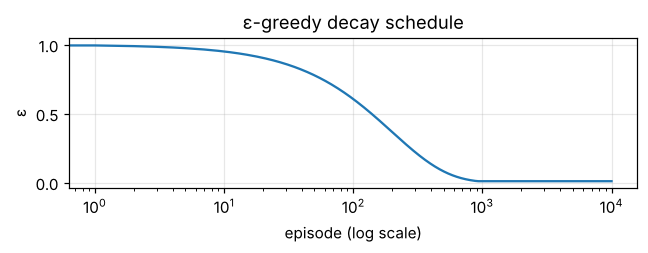

In [9]:
def epsilon_schedule(episode, cfg=CONFIG):
    """Exponentially decaying exploration rate: eps_k = max(eps_min, eps_start * eps_decay**k)."""
    return max(cfg["eps_min"], cfg["eps_start"] * cfg["eps_decay"] ** episode)

def make_validation_states(cfg=CONFIG):
    """Sample the fixed validation set ONCE (uniform over the observation box, own seed)."""
    rng = np.random.default_rng(cfg["val_seed"])                      # dedicated seed, not shared with training
    return rng.uniform(_space.low, _space.high, size=(cfg["n_val_states"], 2))   # (N, 2) array of states

VAL_STATES = make_validation_states()                                 # sampled once, never changed
VAL_IDX = DISC.batch(VAL_STATES)                                      # pre-computed bin indices
print("Validation set:", VAL_STATES.shape, "| first 3 states:\n", VAL_STATES[:3].round(4))
print("eps at episodes 0 / 100 / 500 / 919 / 5000:",
      [round(epsilon_schedule(k), 4) for k in (0, 100, 500, 919, 5000)])

fig, ax = plt.subplots(figsize=(6, 2.4))                              # small plot of the schedule
ax.plot([epsilon_schedule(k) for k in range(CONFIG["n_episodes"])])   # eps per episode
ax.set(xscale="log", xlabel="episode (log scale)", ylabel="ε", title="ε-greedy decay schedule")
plt.tight_layout(); plt.show()

In [10]:
class TabularTDAgent:
    """
    Base class for one-step tabular TD control with an epsilon-greedy policy.
    Sub-classes differ ONLY in td_target(); everything else is shared.
    """
    name = "TD"

    def __init__(self, n_pos, n_vel, n_actions, alpha, gamma, rng):
        self.Q = np.zeros((n_pos, n_vel, n_actions))                  # Q-table initialised to zero
        self.alpha, self.gamma = alpha, gamma                         # learning rate, discount
        self.n_actions = n_actions                                    # |A| = 3
        self.rng = rng                                                # agent RNG (exploration + tie-breaking)

    def act(self, s, epsilon):
        """Epsilon-greedy action in discrete state s, with random tie-breaking among maximisers."""
        if self.rng.random() < epsilon:                               # explore with probability epsilon
            return int(self.rng.integers(self.n_actions))
        q = self.Q[s]                                                 # action values in state s
        best = np.flatnonzero(q == q.max())                           # all greedy actions
        return int(best[0]) if len(best) == 1 else int(self.rng.choice(best))   # break ties at random

    def greedy(self, s):
        """Deterministic greedy action (epsilon = 0) used for evaluation and policy maps."""
        return int(np.argmax(self.Q[s]))

    def td_target(self, r, s_next, a_next, terminated):
        """TD target; implemented by the sub-classes."""
        raise NotImplementedError

    def update(self, s, a, r, s_next, a_next, terminated):
        """One TD(0) update of Q(s, a); returns the TD error."""
        target = self.td_target(r, s_next, a_next, terminated)        # algorithm-specific target
        td_error = target - self.Q[s][a]                              # delta = target - Q(s, a)
        self.Q[s][a] += self.alpha * td_error                         # Q(s,a) <- Q(s,a) + alpha * delta
        return td_error


class QLearningAgent(TabularTDAgent):
    """Off-policy TD control: bootstrap from the greedy value max_a' Q(s', a')."""
    name = "Q-learning"

    def td_target(self, r, s_next, a_next, terminated):
        """R if terminated, else R + gamma * max_a' Q(s', a'). (a_next is ignored: off-policy.)"""
        if terminated:                                                # true terminal state: no bootstrap
            return r
        return r + self.gamma * np.max(self.Q[s_next])                # greedy bootstrap


class SarsaAgent(TabularTDAgent):
    """On-policy TD control: bootstrap from the action a' actually chosen by the epsilon-greedy policy."""
    name = "SARSA"

    def td_target(self, r, s_next, a_next, terminated):
        """R if terminated, else R + gamma * Q(s', a') with a' from the behaviour policy."""
        if terminated:                                                # true terminal state: no bootstrap
            return r
        return r + self.gamma * self.Q[s_next][a_next]                # on-policy bootstrap

In [11]:
def train_agent(agent_cls, modified, seed=SEED, cfg=CONFIG, verbose=True):
    """
    Train one tabular agent for cfg['n_episodes'] episodes.

    The loop is identical for Q-learning and SARSA: a' is chosen from s' with the same epsilon-greedy
    policy before the update; only agent.td_target() differs. Returns (agent, per-episode DataFrame).
    """
    env = make_env(modified)                                          # original or modified env
    agent = agent_cls(cfg["pos_bins"], cfg["vel_bins"], 3, cfg["alpha"], cfg["gamma"],
                      np.random.default_rng(seed))                    # agent RNG seeded identically for all runs
    vi, vj = VAL_IDX                                                  # fixed validation-state indices
    tag = f"{agent.name} | {'MODIFIED' if modified else 'ORIGINAL'} env"
    rows, t0 = [], time.time()                                        # per-episode log, timer
    for ep in range(cfg["n_episodes"]):
        eps = epsilon_schedule(ep, cfg)                               # exploration rate for this episode
        obs, _ = env.reset(seed=seed if ep == 0 else None)            # seed once; later resets continue the stream
        s = DISC(obs)                                                 # discretise start state
        a = agent.act(s, eps)                                         # first action
        G, steps, pushes, abs_td = 0.0, 0, 0, 0.0                     # episode accumulators
        while True:
            pushes += int(a != 1)                                     # count SELECTED push actions
            obs2, r, terminated, truncated, _ = env.step(a)           # interact (executed action is hidden)
            s2 = DISC(obs2)                                           # discretise next state
            a2 = agent.act(s2, eps)                                   # next action from the behaviour policy
            abs_td += abs(agent.update(s, a, r, s2, a2, terminated))  # TD update (target differs per algorithm)
            G += r; steps += 1                                        # return and length
            if terminated or truncated:                               # episode end (terminal or time-out)
                break
            s, a = s2, a2                                             # move on: S <- S', A <- A'
        success = bool(terminated)                                    # flag reached
        gentle = bool(terminated and not truncated and obs2[0] >= 0.5 and obs2[1] <= 0.03)  # gentle-arrival criterion
        avg_max_q = float(agent.Q[vi, vj].max(axis=1).mean())         # mean_s max_a Q(s,a) on validation set
        rows.append(dict(episode=ep, reward=G, length=steps, success=success, gentle=gentle,
                         pushes=pushes, arrival_v=float(obs2[1]) if success else np.nan,
                         avg_max_q=avg_max_q, epsilon=eps, mean_abs_td=abs_td / steps))
        if verbose and (ep + 1) % cfg["log_every"] == 0:              # periodic training log
            w = pd.DataFrame(rows[-cfg["log_every"]:])                # last 100 episodes
            print(f"[{tag}] ep {ep+1:5d} | eps {eps:.3f} | R(avg100) {w.reward.mean():8.2f} | "
                  f"success {w.success.mean():4.0%} | gentle {w.gentle.mean():4.0%} | "
                  f"pushes {w.pushes.mean():6.1f} | len {w.length.mean():5.1f} | avg max Q {avg_max_q:8.2f}")
    log = pd.DataFrame(rows)                                          # full per-episode log
    log.to_csv(f"{OUT_DIR}/log_{agent.name}_{'modified' if modified else 'original'}_seed{seed}.csv", index=False)
    if verbose:
        print(f"[{tag}] finished {cfg['n_episodes']} episodes in {time.time()-t0:.1f}s; "
              f"Q-table visited states: {(np.abs(agent.Q).sum(axis=2) > 0).sum()}/{agent.Q.shape[0]*agent.Q.shape[1]}")
    return agent, log

AGENTS, LOGS = {}, {}                                                 # trained agents and their logs, by label

### Training Q-learning on the modified and the original environment
Same seed (42), discretisation, α, γ, ε-schedule and number of episodes (10,000) in both runs. One log line is printed every 100 episodes (each line summarises those 100 episodes). The complete per-episode logs are written to `outputs/log_<algorithm>_<env>_seed<seed>.csv`.

In [12]:
AGENTS["Q-learning | modified"], LOGS["Q-learning | modified"] = train_agent(QLearningAgent, modified=True)

[Q-learning | MODIFIED env] ep   100 | eps 0.609 | R(avg100)  -238.53 | success   0% | gentle   0% | pushes  128.4 | len 200.0 | avg max Q    -0.70


[Q-learning | MODIFIED env] ep   200 | eps 0.369 | R(avg100)  -237.76 | success   0% | gentle   0% | pushes  125.8 | len 200.0 | avg max Q    -1.39


[Q-learning | MODIFIED env] ep   300 | eps 0.223 | R(avg100)  -237.44 | success   0% | gentle   0% | pushes  124.8 | len 200.0 | avg max Q    -2.05


[Q-learning | MODIFIED env] ep   400 | eps 0.135 | R(avg100)  -237.36 | success   0% | gentle   0% | pushes  124.5 | len 200.0 | avg max Q    -2.67


[Q-learning | MODIFIED env] ep   500 | eps 0.082 | R(avg100)  -237.76 | success   1% | gentle   1% | pushes  126.8 | len 200.0 | avg max Q    -3.27


[Q-learning | MODIFIED env] ep   600 | eps 0.050 | R(avg100)  -238.22 | success   0% | gentle   0% | pushes  127.4 | len 200.0 | avg max Q    -3.84


... (90 outputs left out)

[Q-learning | MODIFIED env] ep  9700 | eps 0.010 | R(avg100)  -150.23 | success  92% | gentle  91% | pushes   93.0 | len 145.1 | avg max Q   -24.75


[Q-learning | MODIFIED env] ep  9800 | eps 0.010 | R(avg100)  -144.38 | success  97% | gentle  97% | pushes   88.0 | len 142.2 | avg max Q   -24.74


[Q-learning | MODIFIED env] ep  9900 | eps 0.010 | R(avg100)  -146.28 | success  96% | gentle  96% | pushes   91.0 | len 143.0 | avg max Q   -24.75


[Q-learning | MODIFIED env] ep 10000 | eps 0.010 | R(avg100)  -153.30 | success  88% | gentle  88% | pushes   94.4 | len 147.0 | avg max Q   -24.79
[Q-learning | MODIFIED env] finished 10000 episodes in 35.9s; Q-table visited states: 711/1008


In [13]:
AGENTS["Q-learning | original"], LOGS["Q-learning | original"] = train_agent(QLearningAgent, modified=False)

[Q-learning | ORIGINAL env] ep   100 | eps 0.609 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  136.3 | len 200.0 | avg max Q    -0.60


[Q-learning | ORIGINAL env] ep   200 | eps 0.369 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  137.3 | len 200.0 | avg max Q    -1.16


[Q-learning | ORIGINAL env] ep   300 | eps 0.223 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  139.2 | len 200.0 | avg max Q    -1.73


[Q-learning | ORIGINAL env] ep   400 | eps 0.135 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  141.1 | len 200.0 | avg max Q    -2.26


[Q-learning | ORIGINAL env] ep   500 | eps 0.082 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  142.0 | len 200.0 | avg max Q    -2.78


[Q-learning | ORIGINAL env] ep   600 | eps 0.050 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  141.4 | len 200.0 | avg max Q    -3.29


... (90 outputs left out)

[Q-learning | ORIGINAL env] ep  9700 | eps 0.010 | R(avg100)  -164.15 | success  98% | gentle   8% | pushes  129.6 | len 164.2 | avg max Q   -24.76


[Q-learning | ORIGINAL env] ep  9800 | eps 0.010 | R(avg100)  -169.09 | success  95% | gentle   6% | pushes  133.1 | len 169.1 | avg max Q   -24.86


[Q-learning | ORIGINAL env] ep  9900 | eps 0.010 | R(avg100)  -168.66 | success  83% | gentle  12% | pushes  130.6 | len 168.7 | avg max Q   -24.96


[Q-learning | ORIGINAL env] ep 10000 | eps 0.010 | R(avg100)  -155.82 | success  84% | gentle  47% | pushes  126.2 | len 155.8 | avg max Q   -25.01
[Q-learning | ORIGINAL env] finished 10000 episodes in 30.1s; Q-table visited states: 732/1008


---
# Part (c): SARSA
Same class hierarchy, same training loop, same seed, discretisation, zero initialisation, α, γ, ε-schedule and episode count. The **only** code difference is `SarsaAgent.td_target()`, which uses `Q(s′, a′)` for the action `a′` the ε-greedy policy actually chose, instead of `max_a′ Q(s′, a′)`. The cell after training checks this programmatically.

In [14]:
AGENTS["SARSA | modified"], LOGS["SARSA | modified"] = train_agent(SarsaAgent, modified=True)

[SARSA | MODIFIED env] ep   100 | eps 0.609 | R(avg100)  -238.39 | success   0% | gentle   0% | pushes  128.0 | len 200.0 | avg max Q    -0.81


[SARSA | MODIFIED env] ep   200 | eps 0.369 | R(avg100)  -237.99 | success   0% | gentle   0% | pushes  126.6 | len 200.0 | avg max Q    -1.53


[SARSA | MODIFIED env] ep   300 | eps 0.223 | R(avg100)  -238.03 | success   0% | gentle   0% | pushes  126.8 | len 200.0 | avg max Q    -2.19


[SARSA | MODIFIED env] ep   400 | eps 0.135 | R(avg100)  -238.00 | success   0% | gentle   0% | pushes  126.7 | len 200.0 | avg max Q    -2.83


[SARSA | MODIFIED env] ep   500 | eps 0.082 | R(avg100)  -238.01 | success   0% | gentle   0% | pushes  126.7 | len 200.0 | avg max Q    -3.44


[SARSA | MODIFIED env] ep   600 | eps 0.050 | R(avg100)  -238.67 | success   0% | gentle   0% | pushes  128.9 | len 200.0 | avg max Q    -4.02


... (90 outputs left out)

[SARSA | MODIFIED env] ep  9700 | eps 0.010 | R(avg100)  -182.82 | success  78% | gentle  78% | pushes  101.0 | len 172.0 | avg max Q   -25.97


[SARSA | MODIFIED env] ep  9800 | eps 0.010 | R(avg100)  -189.86 | success  84% | gentle  79% | pushes  102.2 | len 179.0 | avg max Q   -26.06


[SARSA | MODIFIED env] ep  9900 | eps 0.010 | R(avg100)  -180.70 | success  96% | gentle  95% | pushes   94.2 | len 176.2 | avg max Q   -26.16


[SARSA | MODIFIED env] ep 10000 | eps 0.010 | R(avg100)  -183.31 | success  87% | gentle  87% | pushes   98.7 | len 175.4 | avg max Q   -26.21
[SARSA | MODIFIED env] finished 10000 episodes in 34.2s; Q-table visited states: 709/1008


In [15]:
AGENTS["SARSA | original"], LOGS["SARSA | original"] = train_agent(SarsaAgent, modified=False)

[SARSA | ORIGINAL env] ep   100 | eps 0.609 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  135.9 | len 200.0 | avg max Q    -0.67


[SARSA | ORIGINAL env] ep   200 | eps 0.369 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  138.0 | len 200.0 | avg max Q    -1.28


[SARSA | ORIGINAL env] ep   300 | eps 0.223 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  139.4 | len 200.0 | avg max Q    -1.85


[SARSA | ORIGINAL env] ep   400 | eps 0.135 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  140.8 | len 200.0 | avg max Q    -2.38


[SARSA | ORIGINAL env] ep   500 | eps 0.082 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  140.4 | len 200.0 | avg max Q    -2.92


[SARSA | ORIGINAL env] ep   600 | eps 0.050 | R(avg100)  -200.00 | success   0% | gentle   0% | pushes  141.1 | len 200.0 | avg max Q    -3.43


... (90 outputs left out)

[SARSA | ORIGINAL env] ep  9700 | eps 0.010 | R(avg100)  -157.00 | success  92% | gentle   1% | pushes  132.9 | len 157.0 | avg max Q   -24.91


[SARSA | ORIGINAL env] ep  9800 | eps 0.010 | R(avg100)  -152.85 | success  89% | gentle  19% | pushes  127.9 | len 152.8 | avg max Q   -24.98


[SARSA | ORIGINAL env] ep  9900 | eps 0.010 | R(avg100)  -157.27 | success  83% | gentle  24% | pushes  128.2 | len 157.3 | avg max Q   -25.05


[SARSA | ORIGINAL env] ep 10000 | eps 0.010 | R(avg100)  -170.49 | success  85% | gentle   1% | pushes  143.8 | len 170.5 | avg max Q   -25.15
[SARSA | ORIGINAL env] finished 10000 episodes in 27.7s; Q-table visited states: 730/1008


In [16]:
# Programmatic check that the two algorithms differ only in the TD target.
own_methods = lambda cls: sorted(k for k, v in vars(cls).items() if callable(v))   # methods defined in the class itself
print("Methods overridden by QLearningAgent:", own_methods(QLearningAgent))
print("Methods overridden by SarsaAgent    :", own_methods(SarsaAgent))
print("Shared training loop / config       : train_agent(...) with CONFIG, seed =", SEED)

# Same seed => identical behaviour until the Q-tables first disagree: find the first diverging episode.
for env_label in ("modified", "original"):
    lq, ls = LOGS[f"Q-learning | {env_label}"], LOGS[f"SARSA | {env_label}"]
    diff = np.flatnonzero((lq.reward.values != ls.reward.values) | (lq.length.values != ls.length.values))
    print(f"{env_label:8s} env: Q-learning and SARSA episodes identical up to episode {diff[0] if len(diff) else 'end'}")

Methods overridden by QLearningAgent: ['td_target']
Methods overridden by SarsaAgent    : ['td_target']
Shared training loop / config       : train_agent(...) with CONFIG, seed = 42
modified env: Q-learning and SARSA episodes identical up to episode 5
original env: Q-learning and SARSA episodes identical up to episode 904


---
# Part (d): Performance evaluation

Colour code used in every figure: **blue = Q-learning**, **orange = SARSA**. In two-panel figures the left panel is the original env and the right panel is the modified (sticky) env. Faint lines are raw per-episode values, bold lines are 100-episode moving averages.

In [17]:
LABELS = ["Q-learning | original", "SARSA | original", "Q-learning | modified", "SARSA | modified"]   # fixed order
COLORS = {"Q-learning": "tab:blue", "SARSA": "tab:orange"}             # one colour per algorithm

def moving_average(x, w=100):
    """Trailing moving average over the previous w episodes (shorter window at the start)."""
    return pd.Series(np.asarray(x, dtype=float)).rolling(w, min_periods=1).mean().values

def two_panel(metric, ylabel, title, raw=True, transform=None, ylim=None):
    """Plot `metric` for both algorithms: left panel original env, right panel modified env."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
    for ax, env_label in zip(axes, ["original", "modified"]):
        for algo in ["Q-learning", "SARSA"]:
            y = LOGS[f"{algo} | {env_label}"][metric].astype(float).values   # per-episode metric
            y = transform(y) if transform else y                             # optional transform
            if raw:
                ax.plot(y, color=COLORS[algo], alpha=0.12, lw=0.5)           # raw values (faint)
            ax.plot(moving_average(y), color=COLORS[algo], lw=1.8, label=f"{algo} (MA-100)")   # moving average
        ax.set(title=f"{title} | {env_label.upper()} env", xlabel="training episode", ylabel=ylabel)
        if ylim: ax.set_ylim(*ylim)
        ax.legend(loc="lower right")
    plt.tight_layout(); fig.savefig(f"{OUT_DIR}/{metric}.png", bbox_inches="tight"); plt.show()

def window_stats(lo, hi):
    """Table of mean training metrics over episodes [lo, hi) for the four agents."""
    out = {}
    for lab in LABELS:
        w = LOGS[lab].iloc[lo:hi]                                             # episode window
        out[lab] = dict(reward=w.reward.mean(), success=w.success.mean(), gentle=w.gentle.mean(),
                        pushes=w.pushes.mean(), length=w.length.mean(),
                        push_frac=(w.pushes / w.length).mean(), arrival_v=w.arrival_v.mean(),
                        avg_max_q=w.avg_max_q.iloc[-1])
    return pd.DataFrame(out).T

# Learning-speed summary: first episode at which the MA-100 success rate reaches 50% and 90%.
speed = {lab: {f"first ep MA-100 success ≥ {int(th*100)}%":
               int(np.argmax(moving_average(LOGS[lab].success) >= th)) if (moving_average(LOGS[lab].success) >= th).any() else None
               for th in (0.5, 0.9)} for lab in LABELS}
print(pd.DataFrame(speed).T.to_string())
N_EP = CONFIG["n_episodes"]                                                  # total training episodes
print(f"\nTraining metrics over the last 1,000 episodes ({N_EP-1000}-{N_EP-1}):")
LAST = window_stats(N_EP - 1000, N_EP)
print(LAST.to_string(float_format="%.3f"))

                       first ep MA-100 success ≥ 50%  first ep MA-100 success ≥ 90%
Q-learning | original                           2778                           3508
SARSA | original                                2695                           3639
Q-learning | modified                           4029                           5518
SARSA | modified                                3727                           5270

Training metrics over the last 1,000 episodes (9000-9999):
                        reward  success  gentle  pushes  length  push_frac  arrival_v  avg_max_q
Q-learning | original -155.124    0.958   0.234 124.899 155.124      0.809      0.034    -25.008
SARSA | original      -157.988    0.936   0.110 131.508 157.988      0.835      0.041    -25.150
Q-learning | modified -154.614    0.947   0.944  96.567 149.244      0.652      0.019    -24.788
SARSA | modified      -175.414    0.904   0.893  98.059 168.321      0.585      0.019    -26.206


### Plot 1: Episode reward vs. training episode (MA-100)

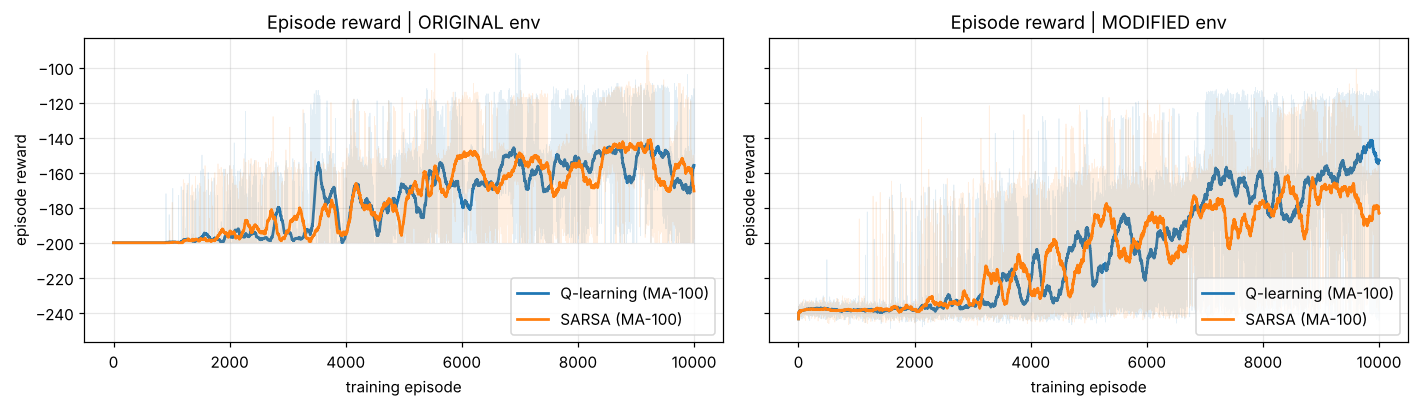

In [18]:
two_panel("reward", "episode reward", "Episode reward")

**Interpretation (reward).**
* **Starting levels differ by design.** In the original env, a failed episode scores exactly −200. In the modified env, the early random-like policy scores ≈ −238, which is 200 steps × (−1) plus about 128 selected pushes × (−0.3). Absolute rewards should therefore be compared *within* a panel, not across panels.
* **The sticky env learns later.** The MA-100 success rate first reaches 50% at episode 2,778 (Q-learning) / 2,695 (SARSA) in the original env, but only at 4,029 / 3,727 in the modified env. For 90% the episodes are 3,508 / 3,639 vs. 5,518 / 5,270. The sticky actuator and the sparser, larger bonus signal delay learning by roughly 1,000–2,000 episodes.
* **Q-learning vs. SARSA.** In the original env both algorithms end at a similar level: last-1,000-episode mean −155.1 (Q) vs. −158.0 (SARSA). In the modified env Q-learning ends clearly higher on this seed, −154.6 vs. −175.4, because it collects the +25 bonus more often and has shorter episodes (149 vs. 168 steps). The multi-seed check in Extra 3 shows that this particular gap does **not** generalise across seeds.
* **Both curves in the modified env are more jagged** (larger dips after the first successes), which matches the stability numbers in E2.

### Plot 2: Average predicted value, mean over validation states of max_a Q(s,a)
The validation set is the 1,000 states sampled once before training (seed 7) and never changed. The right panel shows the Q-learning minus SARSA **gap** in both environments.

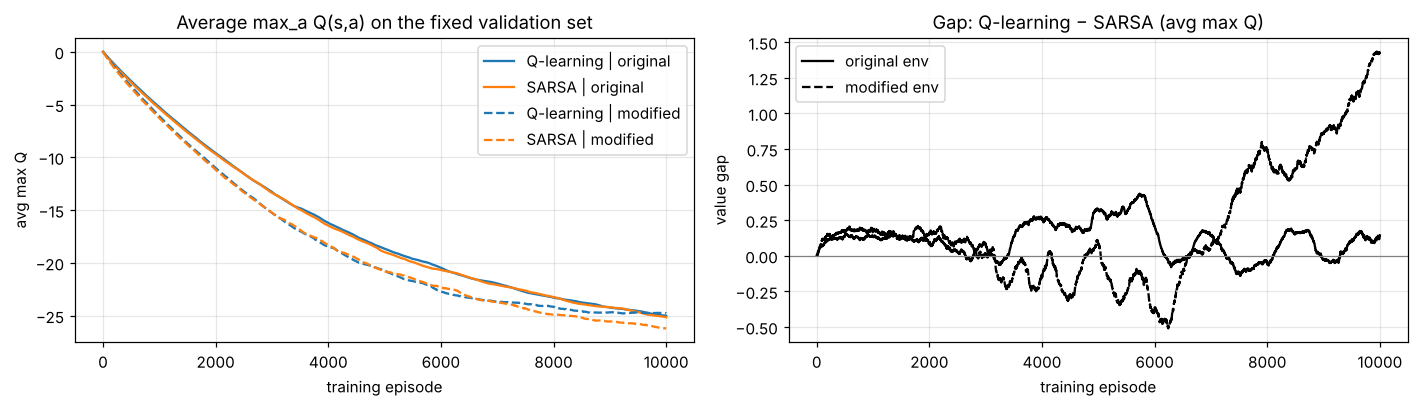

          final Q-learning  final SARSA  final gap  mean gap (last 2000 ep)  mean |gap| (last 2000 ep)
original           -25.008      -25.150      0.142                    0.082                      0.097
modified           -24.788      -26.206      1.418                    0.883                      0.883


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for lab in LABELS:
    algo, env_label = lab.split(" | ")                                       # parse the label
    axes[0].plot(LOGS[lab].avg_max_q, color=COLORS[algo], ls="-" if env_label == "original" else "--",
                 label=lab)                                                  # avg max-Q curve
axes[0].set(title="Average max_a Q(s,a) on the fixed validation set", xlabel="training episode", ylabel="avg max Q")
axes[0].legend()
for env_label, ls in [("original", "-"), ("modified", "--")]:
    gap = LOGS[f"Q-learning | {env_label}"].avg_max_q - LOGS[f"SARSA | {env_label}"].avg_max_q   # value gap
    axes[1].plot(gap, color="k", ls=ls, label=f"{env_label} env")
axes[1].axhline(0, color="grey", lw=0.8)                                     # zero-gap reference
axes[1].set(title="Gap: Q-learning − SARSA (avg max Q)", xlabel="training episode", ylabel="value gap")
axes[1].legend(); plt.tight_layout(); fig.savefig(f"{OUT_DIR}/avg_max_q.png", bbox_inches="tight"); plt.show()

gap_tab = {}
for env_label in ("original", "modified"):
    g = (LOGS[f"Q-learning | {env_label}"].avg_max_q - LOGS[f"SARSA | {env_label}"].avg_max_q).values   # gap series
    gap_tab[env_label] = {"final Q-learning": LOGS[f"Q-learning | {env_label}"].avg_max_q.iloc[-1],
                          "final SARSA": LOGS[f"SARSA | {env_label}"].avg_max_q.iloc[-1],
                          "final gap": g[-1], "mean gap (last 2000 ep)": g[-2000:].mean(),
                          "mean |gap| (last 2000 ep)": np.abs(g[-2000:]).mean()}
GAP = pd.DataFrame(gap_tab).T
print(GAP.to_string(float_format="%.3f"))

**Interpretation (predicted value).**
* All four curves fall smoothly from the optimistic initial value 0 toward ≈ −25. The validation states are uniform over the whole box, and roughly 27–30% of the grid is never visited (Q still 0), so a similar share of validation states contributes 0. The *absolute* level is therefore diluted, but the *comparison* between curves is fair, since every agent is evaluated on the same 1,000 states.
* During episodes ~1,000–7,000 the modified-env curves lie **below** the original ones because every selected push costs an extra 0.3. They catch up later as the +25 gentle-arrival bonus propagates backwards from the flag.
* **Gap Q-learning − SARSA.** In the original env the gap stays small and mostly positive: final 0.14, mean 0.08 over the last 2,000 episodes. In the modified env it swings with a much larger amplitude (−0.5 to +0.4 between episodes 3,000 and 6,500), then grows to **+1.42** at the end, a mean of **0.88** over the last 2,000 episodes, about 10× the original. A positive gap is expected, because Q-learning bootstraps from `max` (optimistic, subject to maximisation bias) and SARSA from the action actually taken. Discussion Q1 analyses whether stickiness enlarges it.

### Plot 3: Success rate and gentle-arrival rate (MA-100)
"Gentle arrival" uses the same criterion in both environments (terminated, not truncated, x ≥ 0.5, v ≤ 0.03). It is *rewarded* only in the modified env.

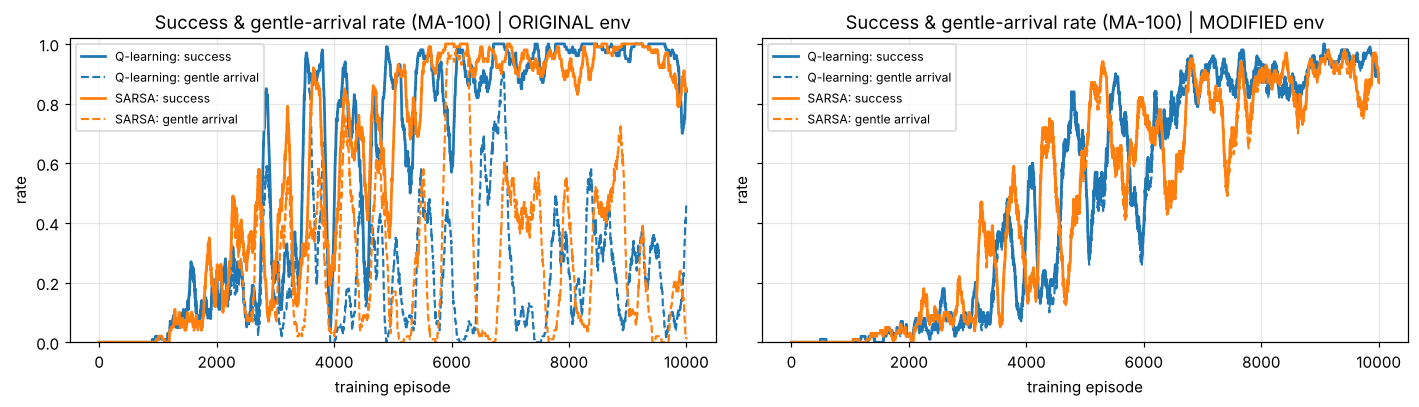

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, env_label in zip(axes, ["original", "modified"]):
    for algo in ["Q-learning", "SARSA"]:
        L = LOGS[f"{algo} | {env_label}"]                                     # log of this agent
        ax.plot(moving_average(L.success), color=COLORS[algo], lw=1.8, label=f"{algo}: success")
        ax.plot(moving_average(L.gentle), color=COLORS[algo], lw=1.4, ls="--", label=f"{algo}: gentle arrival")
    ax.set(title=f"Success & gentle-arrival rate (MA-100) | {env_label.upper()} env",
           xlabel="training episode", ylabel="rate", ylim=(0, 1.02))
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/success_gentle.png", bbox_inches="tight"); plt.show()

**Interpretation (success and gentle arrival).**
* **Original env.** Success climbs to ≈ 95–100% (last 1,000 episodes: Q 95.8%, SARSA 93.6%), but the gentle-arrival rate swings almost randomly between 0% and 100%. Nothing in the original reward distinguishes a slow arrival from a fast one, so whether the greedy path happens to arrive below 0.03 changes every time the policy shifts (last 1,000 episodes: 23.4% Q, 11.0% SARSA).
* **Modified env.** The dashed gentle-arrival line lies almost exactly on the success line (Q 94.4% gentle of 94.7% success, SARSA 89.3% of 90.4%). Practically **every successful arrival is a gentle one**, so the bonus has fully shaped *how* the goal is reached. Learning starts later and shows deeper dips, e.g. Q-learning drops to ≈ 30% around episode 6,000.

### Plot 4: Push actions (0 or 2) selected per episode
Pushes per episode depend on episode length (a failed episode is 200 steps long), so the right figure also shows the **push fraction** = pushes / episode length.

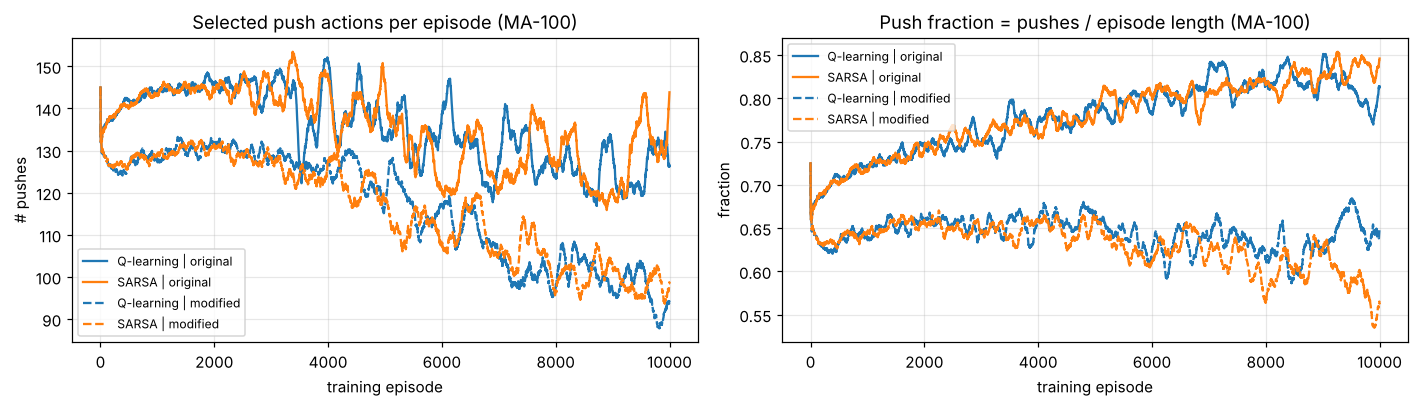

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for lab in LABELS:
    algo, env_label = lab.split(" | ")
    L = LOGS[lab]                                                             # agent log
    ls = "-" if env_label == "original" else "--"                             # solid = original, dashed = modified
    axes[0].plot(moving_average(L.pushes), color=COLORS[algo], ls=ls, label=lab)            # pushes per episode
    axes[1].plot(moving_average(L.pushes / L.length), color=COLORS[algo], ls=ls, label=lab) # push fraction
axes[0].set(title="Selected push actions per episode (MA-100)", xlabel="training episode", ylabel="# pushes")
axes[1].set(title="Push fraction = pushes / episode length (MA-100)", xlabel="training episode", ylabel="fraction")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/pushes.png", bbox_inches="tight"); plt.show()

**Interpretation (push actions).**
* At the start (ε ≈ 1) every agent selects a push about 2/3 of the time (two of three actions are pushes).
* **Original env:** pushing is free, so the push fraction *rises* to 0.80–0.85. Constant energy pumping is the fastest way up the hill. Pushes per episode stay at 120–150 (last 1,000 episodes: Q 124.9, SARSA 131.5).
* **Modified env:** the push fraction never rises above the random level. It stays around 0.60–0.65 and ends at 0.65 (Q) / 0.59 (SARSA), while pushes per episode fall from ≈ 130 to **96.6 (Q) / 98.1 (SARSA)**, about 25% fewer than in the original env. The agents learned to coast (action 1) whenever gravity does the work, which removes ≈ 30 penalised actions per episode.
* Within each environment the two algorithms behave similarly. Late in training SARSA in the modified env has the lowest push fraction, which fits its more conservative value estimates.

### Plot 5: Greedy policy maps (position × velocity)
Each cell is one of the 36 × 28 discrete states, coloured by `argmax_a Q(s,a)`. **Grey = never visited** (all three Q-values still exactly 0). The dashed lines mark the flag (x = 0.5) and the gentle-arrival speed (v = 0.03). Both are exact bin edges because of the chosen discretisation.

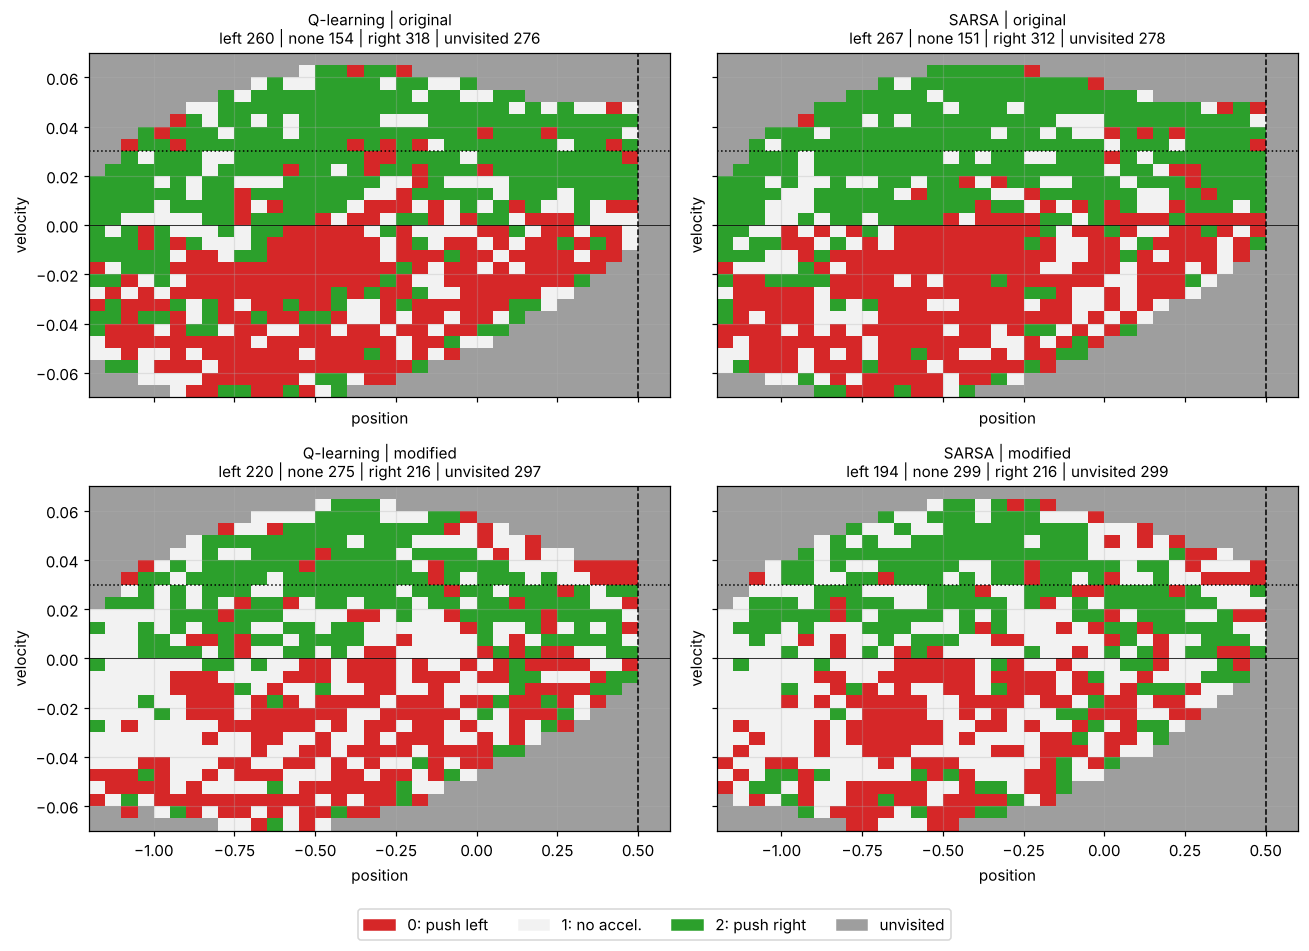

                       visited  all: left  all: none  all: right  x≥0.3: left  x≥0.3: none  x≥0.3: right
Q-learning | original  732.000      0.355      0.210       0.434        0.241        0.222         0.537
SARSA | original       730.000      0.366      0.207       0.427        0.278        0.148         0.574
Q-learning | modified  711.000      0.309      0.387       0.304        0.304        0.304         0.391
SARSA | modified       709.000      0.274      0.422       0.305        0.256        0.419         0.326


In [22]:
def plot_policy_maps():
    """Heat-map of the greedy action for each of the four agents, with unvisited states in grey."""
    pc, vc = DISC.centers()                                                  # bin centres
    cmap = ListedColormap(["#d62728", "#f2f2f2", "#2ca02c", "#9e9e9e"])      # 0=left, 1=none, 2=right, 3=unvisited
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True, sharey=True)
    for ax, lab in zip(axes.flatten(), LABELS):                              # rows: env, columns: algorithm
        Q = AGENTS[lab].Q                                                    # Q-table (pos, vel, action)
        greedy = Q.argmax(axis=2).astype(float)                              # greedy action per state
        greedy[np.all(Q == 0, axis=2)] = 3                                   # mark unvisited states
        ax.imshow(greedy.T, origin="lower", aspect="auto", cmap=cmap, vmin=-0.5, vmax=3.5,
                  extent=[DISC.low[0], DISC.high[0], DISC.low[1], DISC.high[1]])   # x = position, y = velocity
        ax.axvline(0.5, color="k", ls="--", lw=1); ax.axhline(0.03, color="k", ls=":", lw=1)   # flag & gentle speed
        ax.axhline(0.0, color="k", lw=0.5)                                   # zero velocity
        frac = {a: (greedy == a).sum() for a in range(4)}                    # action counts
        ax.set_title(f"{lab}\nleft {frac[0]} | none {frac[1]} | right {frac[2]} | unvisited {frac[3]}", fontsize=10)
        ax.set_xlabel("position"); ax.set_ylabel("velocity")
    fig.legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap.colors, ["0: push left", "1: no accel.", "2: push right", "unvisited"])],
               loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    plt.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(f"{OUT_DIR}/policy_maps.png", bbox_inches="tight"); plt.show()

plot_policy_maps()

def policy_composition():
    """Share of greedy actions among VISITED states, overall and in the 'near-flag' region x >= 0.3."""
    pc, _ = DISC.centers()
    rows = {}
    for lab in LABELS:
        Q = AGENTS[lab].Q; visited = ~np.all(Q == 0, axis=2); g = Q.argmax(axis=2)   # greedy map & visited mask
        near = visited & (pc[:, None] >= 0.3)                                # visited states close to the flag
        rows[lab] = {"visited": int(visited.sum()),
                     **{f"all: {n}": (g[visited] == a).mean() for a, n in enumerate(["left", "none", "right"])},
                     **{f"x≥0.3: {n}": (g[near] == a).mean() for a, n in enumerate(["left", "none", "right"])}}
    return pd.DataFrame(rows).T
print(policy_composition().to_string(float_format="%.3f"))

**Interpretation (greedy policy maps).**
* **Original env (top row):** the classic energy-pumping structure. Mostly *push right* (green) above v = 0 and *push left* (red) below it, with the switching boundary close to v ≈ 0. Coasting (white) covers only ≈ 21% of visited states.
* **Modified env (bottom row):** large white regions. *No acceleration* is greedy in **39% (Q-learning) and 42% (SARSA)** of visited states, against 21% in the original env. Coasting dominates at low |v| and on the left slope, where gravity alone accelerates the car.
* **Braking near the flag:** in the top-right corner (x > 0.3, v ≥ 0.03, just above the dotted gentle-speed line) the modified-env maps contain red/white cells (push left or coast). These states would arrive too fast, so the agent bleeds off speed to earn the +25. The original maps push right there.
* Q-learning and SARSA maps are qualitatively similar within each environment. SARSA's modified map has the most coasting, consistent with the push-count plot.
* About 28–30% of the grid is grey (never visited). These are physically unreachable combinations, e.g. high speed at the far left wall or high negative speed near the flag.

### Greedy evaluation (ε = 0) over 100 fixed-seed test episodes
Each final greedy policy is run on its **own training environment** with test seeds 10000–10099. These seeds fix the start state and, in the modified env, the actuator noise, so all agents of one environment face exactly the same 100 test conditions.

In [23]:
def evaluate(agent, modified, cfg=CONFIG):
    """Run the greedy policy for cfg['n_eval_episodes'] fixed-seed episodes; return per-episode results."""
    env = make_env(modified)                                                 # fresh env for testing
    rows = []
    for i in range(cfg["n_eval_episodes"]):
        obs, _ = env.reset(seed=cfg["eval_seed0"] + i)                       # fixed test seed
        G, steps, pushes = 0.0, 0, 0
        while True:
            a = agent.greedy(DISC(obs))                                      # epsilon = 0
            pushes += int(a != 1)                                            # count selected pushes
            obs, r, te, tr, _ = env.step(a)                                  # interact
            G += r; steps += 1
            if te or tr: break
        rows.append(dict(reward=G, length=steps, success=bool(te), pushes=pushes,
                         gentle=bool(te and not tr and obs[0] >= 0.5 and obs[1] <= 0.03),
                         arrival_v=float(obs[1]) if te else np.nan))
    return pd.DataFrame(rows)

def summarise_eval(df):
    """Aggregate evaluation episodes into the metrics required by the assignment (+ a few extras)."""
    return {"mean reward": df.reward.mean(), "std reward": df.reward.std(), "success rate": df.success.mean(),
            "gentle-arrival rate": df.gentle.mean(), "mean episode length": df.length.mean(),
            "mean pushes": df.pushes.mean(), "mean arrival v": df.arrival_v.mean(),
            "max arrival v": df.arrival_v.max()}

EVAL = {lab: evaluate(AGENTS[lab], modified=lab.endswith("modified")) for lab in LABELS}   # run all four
EVAL_TABLE = pd.DataFrame({lab: summarise_eval(EVAL[lab]) for lab in LABELS}).T
EVAL_TABLE.index.name = "agent | environment"
EVAL_TABLE.to_csv(f"{OUT_DIR}/greedy_eval.csv")
print(EVAL_TABLE.to_string(float_format="%.3f"))
for lab in LABELS:                                                           # arrivals on the 200th step are also truncated
    e = EVAL[lab]; n200 = int((e.success & (e.length == 200)).sum())
    if n200: print(f"{lab}: {n200} arrival(s) on step 200 (terminated AND truncated -> not a gentle arrival by the spec)")

                       mean reward  std reward  success rate  gentle-arrival rate  mean episode length  mean pushes  mean arrival v  max arrival v
agent | environment                                                                                                                               
Q-learning | original     -140.590      21.319         1.000                0.750              140.590      117.630           0.028          0.041
SARSA | original          -175.690      21.422         0.570                0.000              175.690      142.530           0.044          0.044
Q-learning | modified     -151.768      36.193         0.930                0.920              146.850       93.060           0.019          0.027
SARSA | modified          -174.632      26.143         0.850                0.850              169.020       89.540           0.016          0.029
Q-learning | modified: 1 arrival(s) on step 200 (terminated AND truncated -> not a gentle arrival by the spec)


**Interpretation (greedy test table).**
* **Original env:** greedy Q-learning reaches the flag in **100%** of the 100 test episodes (mean length 140.6). Greedy SARSA reaches it in only **57%** (length 175.7), even though it succeeded in 93.6% of its last 1,000 training episodes. During training the 1% exploration and random tie-breaking push the car out of a few looping state cycles. The deterministic greedy policy cannot escape them for 43 of the 100 start states. The 75% gentle arrivals of Q-learning here are incidental, since no bonus exists in this env.
* **Modified env:** Q-learning 93% success / 92% gentle (length 146.9, 93 pushes), SARSA 85% / 85% (length 169.0, 89.5 pushes). Every arrival had v ≤ 0.029. The one Q-learning success that is not counted as gentle happened on the 200th step, where `truncated` is also True. By the specification that is not a gentle arrival.
* **Original vs. modified:** the modified agents need slightly more steps but ≈ 25% fewer pushes, and they arrive gently almost every time. On this seed Q-learning is the stronger greedy policy in both environments. Extra 3 checks whether that holds across seeds.

### Extra 1: Arrival-speed statistics
These support Discussion Q3. The histograms show the velocity at the moment the car reaches the flag, in the greedy test episodes and in the last 1,000 training episodes.

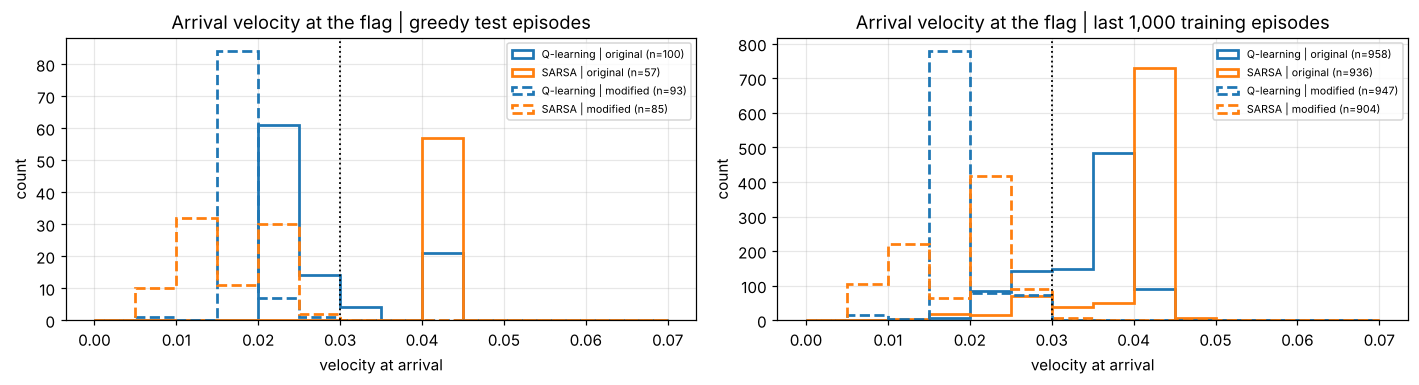

                       arrivals (last 1000 ep)  mean v  median v  share v ≤ 0.03  test mean v
Q-learning | original                 958.0000  0.0338    0.0353          0.2443       0.0278
SARSA | original                      936.0000  0.0407    0.0440          0.1175       0.0445
Q-learning | modified                 947.0000  0.0192    0.0187          0.9989       0.0187
SARSA | modified                      904.0000  0.0186    0.0212          0.9945       0.0164


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharex=True)
bins = np.arange(0, 0.0701, 0.005)                                           # velocity bins aligned with the grid
for ax, (title, source) in zip(axes, [("greedy test episodes", EVAL),
                                      ("last 1,000 training episodes", {l: LOGS[l].iloc[-1000:] for l in LABELS})]):
    for lab in LABELS:
        algo, env_label = lab.split(" | ")
        v = source[lab].arrival_v.dropna()                                   # arrival velocities
        ax.hist(v, bins=bins, histtype="step", lw=1.8, color=COLORS[algo],
                ls="-" if env_label == "original" else "--", label=f"{lab} (n={len(v)})")
    ax.axvline(0.03, color="k", ls=":", lw=1.2)                              # gentle threshold
    ax.set(title=f"Arrival velocity at the flag | {title}", xlabel="velocity at arrival", ylabel="count")
    ax.legend(fontsize=7)
plt.tight_layout(); fig.savefig(f"{OUT_DIR}/arrival_velocity.png", bbox_inches="tight"); plt.show()

arr = {}
for lab in LABELS:
    v = LOGS[lab].iloc[-1000:].arrival_v.dropna()                            # last 1,000 training arrivals
    arr[lab] = {"arrivals (last 1000 ep)": len(v), "mean v": v.mean(), "median v": v.median(),
                "share v ≤ 0.03": (v <= 0.03).mean(), "test mean v": EVAL[lab].arrival_v.mean()}
ARR = pd.DataFrame(arr).T
print(ARR.to_string(float_format="%.4f"))

### Extra 2: Robustness cross-evaluation
"Robust RL" asks whether a policy survives the sticky actuator. Each greedy policy is evaluated in **both** environments with the same 100 test seeds. Rewards are not comparable across environments because the reward functions differ, so the table reports success, gentle-arrival rate and length.

In [25]:
cross = {}
for lab in LABELS:
    for test_env in ("original", "modified"):
        s = summarise_eval(evaluate(AGENTS[lab], modified=(test_env == "modified")))   # greedy test
        cross[(lab, test_env)] = {k: s[k] for k in ("success rate", "gentle-arrival rate", "mean episode length", "mean pushes")}
CROSS = pd.DataFrame(cross).T
CROSS.index.names = ["trained on", "tested on"]
print(CROSS.to_string(float_format="%.3f"))

                                 success rate  gentle-arrival rate  mean episode length  mean pushes
trained on            tested on                                                                     
Q-learning | original original          1.000                0.750              140.590      117.630
                      modified          0.990                0.740              139.480      116.660
SARSA | original      original          0.570                0.000              175.690      142.530
                      modified          0.610                0.000              176.580      143.890
Q-learning | modified original          1.000                1.000              140.920       88.250
                      modified          0.930                0.920              146.850       93.060
SARSA | modified      original          0.800                0.800              169.120       89.660
                      modified          0.850                0.850              169.020    

**Interpretation (cross-evaluation).**
* Policies trained **without** stickiness survive it: greedy Q-learning(original) keeps 99% success on the sticky env. A 30% chance of delaying an action *switch* by a step costs little in MountainCar, because the energy-pumping policy switches direction only about twice per swing.
* The policy trained **with** the modified reward is the better controller even in the original physics. Q-learning(modified) tested on the original env reaches the flag in 100% of episodes, **100% gently**, in 140.9 steps (vs. 140.6 for the original-trained policy) and with **88 pushes instead of 118**. The gentle, energy-saving behaviour is a property of the learned policy, not of the environment it is run in.
* In this task the reward modification (penalty + bonus) therefore changes behaviour much more than the 30% stickiness does. The stickiness mainly makes learning slower and noisier (see Plots 1 and 3 and E2).

### Extra 3: Multi-seed robustness check (4 additional seeds)
The required experiments use a single seed (42). Single-seed RL comparisons are noisy, so the identical pipeline is repeated with 4 more seeds (101, 202, 303, 404). Everything else is unchanged; the validation set and test seeds stay fixed. The table reports mean ± std over the **5 seeds**, which lets the discussion separate real effects from seed luck.

In [26]:
EXTRA_SEEDS = [101, 202, 303, 404]                                           # additional training seeds

def run_one_seed(args):
    """Train one (algorithm, env, seed) combination quietly and return compact summary statistics."""
    algo_name, modified, seed = args
    cls = QLearningAgent if algo_name == "Q-learning" else SarsaAgent        # pick the algorithm
    agent, log = train_agent(cls, modified, seed=seed, verbose=False)        # same pipeline, different seed
    ev = summarise_eval(evaluate(agent, modified))                           # greedy fixed-seed test
    last = log.iloc[-1000:]                                                  # last 1,000 training episodes
    return dict(algo=algo_name, env="modified" if modified else "original", seed=seed,
                train_success=last.success.mean(), train_gentle=last.gentle.mean(),
                train_length=last.length.mean(), final_avg_max_q=log.avg_max_q.iloc[-1],
                test_success=ev["success rate"], test_gentle=ev["gentle-arrival rate"],
                test_length=ev["mean episode length"], test_reward=ev["mean reward"],
                q_curve=log.avg_max_q.values[::50])                          # down-sampled Q curve for the gap plot

jobs = [(a, m, s) for s in EXTRA_SEEDS for a in ("Q-learning", "SARSA") for m in (True, False)]   # 16 runs
t0 = time.time()
try:                                                                         # parallel where 'fork' is available
    with mp.get_context("fork").Pool(min(len(jobs), max(1, os.cpu_count() or 1))) as pool:
        extra = pool.map(run_one_seed, jobs)
except (ValueError, OSError):                                                # fall back to serial execution
    extra = [run_one_seed(j) for j in jobs]
print(f"{len(jobs)} extra runs finished in {time.time()-t0:.0f}s")

# add the main seed-42 runs computed above (same pipeline, already trained)
for lab in LABELS:
    algo, env_label = lab.split(" | "); log, ev = LOGS[lab], summarise_eval(EVAL[lab]); last = log.iloc[-1000:]
    extra.append(dict(algo=algo, env=env_label, seed=SEED, train_success=last.success.mean(),
                      train_gentle=last.gentle.mean(), train_length=last.length.mean(),
                      final_avg_max_q=log.avg_max_q.iloc[-1], test_success=ev["success rate"],
                      test_gentle=ev["gentle-arrival rate"], test_length=ev["mean episode length"],
                      test_reward=ev["mean reward"], q_curve=log.avg_max_q.values[::50]))
MS = pd.DataFrame(extra)
MS.drop(columns="q_curve").sort_values(["env", "algo", "seed"]).to_csv(f"{OUT_DIR}/multiseed.csv", index=False)
cols = ["train_success", "train_gentle", "train_length", "test_success", "test_gentle", "test_length", "test_reward", "final_avg_max_q"]
agg = MS.groupby(["env", "algo"])[cols].agg(["mean", "std"])
agg.columns = [f"{c} ({s})" for c, s in agg.columns]
print("Per-seed results:")
print(MS.drop(columns="q_curve").sort_values(["env", "algo", "seed"]).to_string(index=False, float_format="%.3f"))
print(f"\nMean and std over {MS.seed.nunique()} seeds:")
print(agg.T.to_string(float_format="%.3f"))

16 extra runs finished in 261s
Per-seed results:
      algo      env  seed  train_success  train_gentle  train_length  final_avg_max_q  test_success  test_gentle  test_length  test_reward
Q-learning modified    42          0.947         0.944       149.244          -24.788         0.930        0.920      146.850     -151.768
Q-learning modified   101          0.910         0.900       163.938          -24.687         0.840        0.820      177.360     -189.614
Q-learning modified   202          0.846         0.827       170.305          -25.723         0.760        0.760      181.270     -195.468
Q-learning modified   303          0.867         0.852       167.601          -24.909         0.970        0.970      151.620     -154.013
Q-learning modified   404          0.821         0.810       168.270          -25.628         0.750        0.740      170.660     -181.272
     SARSA modified    42          0.904         0.893       168.321          -26.206         0.850        0.850     

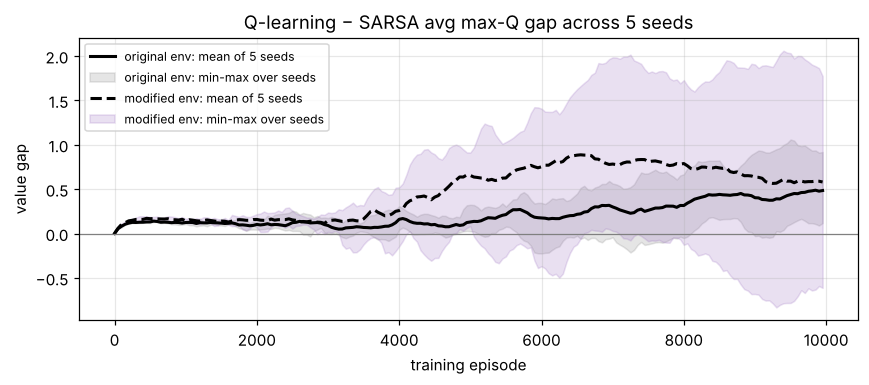

original: mean gap (last 2000 ep) per seed = [0.08 0.39 0.33 0.44 0.87] | mean 0.42 ± 0.29 || mean |gap| per seed = [0.1  0.39 0.33 0.44 0.87] | mean 0.43
modified: mean gap (last 2000 ep) per seed = [ 0.88  1.86 -0.54  0.99  0.08] | mean 0.65 ± 0.92 || mean |gap| per seed = [0.88 1.86 0.54 0.99 0.25] | mean 0.90
Seeds where |gap| is larger in the modified env: 4 of 5


In [27]:
# Q-learning minus SARSA value gap, per seed and averaged, for both environments.
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(0, CONFIG["n_episodes"], 50)                                   # episodes of the down-sampled curves
GAP_MS = {}
for env_label, ls in [("original", "-"), ("modified", "--")]:
    gaps = []
    for seed in [SEED] + EXTRA_SEEDS:
        sel = MS[(MS.env == env_label) & (MS.seed == seed)].set_index("algo")   # both algorithms of one seed
        gaps.append(sel.loc["Q-learning", "q_curve"] - sel.loc["SARSA", "q_curve"])   # gap curve
    gaps = np.array(gaps)
    GAP_MS[env_label] = gaps
    ax.plot(x, gaps.mean(0), color="k", ls=ls, lw=2, label=f"{env_label} env: mean of 5 seeds")
    ax.fill_between(x, gaps.min(0), gaps.max(0), color="tab:gray" if env_label == "original" else "tab:purple",
                    alpha=0.2, label=f"{env_label} env: min-max over seeds")
ax.axhline(0, color="grey", lw=0.8)
ax.set(title="Q-learning − SARSA avg max-Q gap across 5 seeds", xlabel="training episode", ylabel="value gap")
ax.legend(fontsize=8); plt.tight_layout(); fig.savefig(f"{OUT_DIR}/gap_multiseed.png", bbox_inches="tight"); plt.show()
for env_label in ("original", "modified"):
    g = GAP_MS[env_label][:, -40:].mean(1)                                   # mean gap over last 2,000 episodes per seed
    ga = np.abs(GAP_MS[env_label][:, -40:]).mean(1)                          # mean |gap| per seed
    print(f"{env_label:8s}: mean gap (last 2000 ep) per seed = {np.round(g, 2)} | mean {g.mean():.2f} ± {g.std(ddof=1):.2f}"
          f" || mean |gap| per seed = {np.round(ga, 2)} | mean {ga.mean():.2f}")
ga_o, ga_m = (np.abs(GAP_MS[e][:, -40:]).mean(1) for e in ("original", "modified"))   # per-seed |gap|
print(f"Seeds where |gap| is larger in the modified env: {int((ga_m > ga_o).sum())} of {len(ga_m)}")

**Interpretation (5 seeds).**
* **Original env:** Q-learning is better on average: test success 0.972 ± 0.063 vs. 0.888 ± 0.186, mean test reward −146.5 vs. −152.3, training success 0.969 vs. 0.947.
* **Modified env:** the order reverses slightly. SARSA has the higher mean on every outcome metric: training success 0.922 ± 0.031 vs. 0.878 ± 0.050, training gentle rate 0.900 vs. 0.867, test success 0.876 vs. 0.850, test reward −167.3 vs. −174.4. Its seed-to-seed spread in training success is also smaller. All differences are smaller than one standard deviation, so they are a tendency, not a statistically established result.
* The required seed-42 run happens to be one where Q-learning wins in the modified env. This is a concrete example of why single-seed conclusions are fragile (see Discussion Q5).
* **Value gap:** Q-learning's avg max-Q is above SARSA's on average in both environments. The gap is larger under stickiness: mean over the last 2,000 episodes **0.65 ± 0.92 (modified) vs. 0.42 ± 0.29 (original)**, and mean |gap| **0.90 vs. 0.43**, larger in the modified env for **4 of 5 seeds**. The min–max band across seeds is also much wider in the modified env (≈ −0.6 to +2.0 vs. 0 to +0.9). For one seed (202) the modified-env gap is even negative, so stickiness makes the disagreement larger and less predictable rather than adding a fixed offset.

---
# Part (e): Discussion

Two short evidence cells come first. The answers below cite them together with the plots and tables from part (d).

In [28]:
# Evidence E1 (non-Markov observation): same observation + same selected action, different outcome
# depending on the hidden a_prev. Uses the 100,000-step random-policy trace T from Verification 3.
T["v_prev"] = T.groupby("episode").v.shift(1).fillna(0.0)                   # velocity before the step (reset v = 0)
T["dv"] = T.v - T.v_prev                                                    # velocity change caused by this step
P = T[T.a != 1].copy()                                                      # steps where a push was selected
P["executed_as_selected"] = P.a_exec == P.a                                 # did the push reach the physics?
E1 = (P.groupby(["a", "a_prev"])
        .agg(steps=("dv", "size"), **{"P(a_exec = a)": ("executed_as_selected", "mean"), "mean Δv": ("dv", "mean")})
        .reset_index())                                                     # outcome statistics per hidden a_prev
print("Selected push a, hidden previous executed action a_prev -> probability the push is executed and mean Δv")
print(E1.to_string(index=False, float_format="%.5f"))

Selected push a, hidden previous executed action a_prev -> probability the push is executed and mean Δv
 a  a_prev  steps  P(a_exec = a)  mean Δv
 0       0  11112        1.00000 -0.00098
 0       1  11302        0.69669 -0.00069
 0       2  10951        0.70496 -0.00042
 2       0  10940        0.69781  0.00041
 2       1  11349        0.69407  0.00072
 2       2  10949        1.00000  0.00100


In [29]:
# Evidence E2 (stability / noise of learning), seed-42 runs.
E2 = {}
for lab in LABELS:
    L = LOGS[lab]; ma = moving_average(L.success).copy(); late = ma[6000:]  # MA-100 success after episode 6000
    E2[lab] = {"min MA-100 success (ep ≥ 6000)": late.min(), "std MA-100 success (ep ≥ 6000)": late.std(),
               "share of episodes with MA-100 < 0.8": (late < 0.8).mean(),
               "mean |TD error| per step (last 1000 ep)": L.mean_abs_td.iloc[-1000:].mean()}
E2 = pd.DataFrame(E2).T
print(E2.to_string(float_format="%.3f"))

                       min MA-100 success (ep ≥ 6000)  std MA-100 success (ep ≥ 6000)  share of episodes with MA-100 < 0.8  mean |TD error| per step (last 1000 ep)
Q-learning | original                           0.570                           0.066                                0.031                                    0.723
SARSA | original                                0.790                           0.045                                0.002                                    0.980
Q-learning | modified                           0.390                           0.092                                0.126                                    1.032
SARSA | modified                                0.450                           0.122                                0.328                                    1.137


### Q1. Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?
**Yes. It makes the gap clearly larger in magnitude and much more variable, though not a constant offset.**
* *Seed-42 Q-value plot (Plot 2, right panel):* the mean gap over the last 2,000 episodes is **0.88** in the modified env vs. **0.08** in the original (final values 1.42 vs. 0.14). Earlier in training the modified-env gap also oscillates with roughly twice the amplitude of the original one.
* *Five seeds (Extra 3):* mean |gap| over the last 2,000 episodes is **0.90 (modified) vs. 0.43 (original)**, larger in **4 of 5** seeds. The signed mean is 0.65 ± 0.92 vs. 0.42 ± 0.29, and the seed band is about three times wider (gap_multiseed plot). The sign is not guaranteed (seed 202: −0.54), so the reliable effect is a larger and more variable gap.
* *Why.* (i) Q-learning's target `max_a′ Q(s′,a′)` takes a maximum over noisy estimates, which biases it upward (maximisation bias), and the bias grows with the noise in the targets. Under the sticky actuator the same (s, a) leads to different next states depending on the hidden `a_prev` (E1), so the targets get noisier. E2 shows that moving to the modified env raises the per-step |TD error| by **43% for Q-learning** (0.72 → 1.03) but only **16% for SARSA** (0.98 → 1.14). Part of that rise comes from the +25 bonus, which both algorithms share, so the larger relative increase for Q-learning points to its max-based target being hit harder by the extra noise. (ii) SARSA's target uses the action actually selected next and evaluates the policy that is really running, including the exploration and the `a_prev` situations it creates. Its estimates are therefore lower (more conservative): final avg max-Q −26.2 vs. −24.8 on seed 42, and −25.7 vs. −25.1 on average over seeds.

### Q2. Why is the modified environment non-Markovian with respect to the observation, and how does this affect credit assignment?
* **Non-Markov.** The true state of the modified system is **(x, v, a_prev)**, but the agent observes only (x, v). The Markov property requires P(o′, r | o, a) to be independent of the earlier history, and here it is not. E1 measures this directly: with the same selected push `a = 2`, the push is executed with probability **1.00 if a_prev = 2**, but only **0.69–0.70 if a_prev = 0 or 1**. The mean velocity change of that step differs accordingly: **+0.00100** (a_prev = 2), **+0.00072** (a_prev = 1) and **+0.00041** (a_prev = 0). The same holds symmetrically for a = 0. `a_prev` is determined by the agent's previous choice and by earlier random stuck events, i.e. by history the observation does not contain. Two visits to the same (x, v) cell with the same action therefore have different next-state distributions, so the observation process is a POMDP.
* **Effects on credit assignment.**
  1. *Mis-attribution:* when the actuator sticks, the state change that follows step t is caused by the action chosen at step t−1. The TD update still credits or blames Q(s_t, a_t), so the effect of one decision is partly booked on the next one.
  2. *Delayed, stochastic effect of switching:* a decision to change direction takes effect after a geometric delay (on average 0.3/0.7 ≈ 0.43 extra steps). The benefit of a timely switch reaches the value function later and noisily through one-step bootstrapping. This matches the slower learning: 50% success is reached 1,000–1,300 episodes later (Plot 1/3).
  3. *Policy-dependent aliasing:* Q(s, a) becomes an average over the distribution of `a_prev` that the agent's *own* policy produces in s. When the policy changes, that distribution, and with it the "true" value of (s, a), changes too. The targets are non-stationary, which shows up as the deeper dips in Plot 3 and the higher TD errors in E2. SARSA's target stays consistent with the policy that generates the data; Q-learning's `max` assumes a choice whose consequences were learned under a different `a_prev` mix.
  4. The energy penalty is the one *clean* signal: it depends only on the selected action, so it is always credited to the right decision. This is why push reduction is learned reliably (Q3).
* *Possible remedies:* add the last *selected* action to the state (a 36 × 28 × 3 × 3 table), use eligibility traces (SARSA(λ)) to spread credit over the delay, or use a recurrent/history-based state.

### Q3. Do the energy penalty and the gentle-arrival bonus encourage fewer pushes or a slower, more controlled arrival?
**Both, and each mechanism drives a different part of the behaviour.**
* *Fewer pushes (penalty).* In the push-count plot (Plot 4) the push fraction rises to 0.80–0.85 in the original env but stays at 0.59–0.65 in the modified env. Pushes per episode drop from 125/132 to **97/98** (Q/SARSA, last 1,000 episodes), about 25% fewer. In the policy maps (Plot 5), *no acceleration* is greedy in 39–42% of visited states vs. 21% in the original env. The greedy test (table) shows 93/90 pushes vs. 118/143.
* *Slower, controlled arrival (bonus).* From the arrival-speed statistics (Extra 1): mean arrival velocity in the last 1,000 training episodes is **0.019 (modified)** vs. 0.034–0.041 (original), with **99.5–99.9%** of arrivals at v ≤ 0.03 vs. 12–24%. In the greedy tests no modified agent arrived faster than 0.029. The policy maps show braking/coasting cells in the fast near-flag region (x > 0.3, v ≥ 0.03) only in the modified env.
* *"Slower" refers to arrival speed, not total time.* For Q-learning the episode length barely changes (training 149 vs. 155 steps, test 147 vs. 141). The agent saves energy and arrives gently without being much slower overall. SARSA pays somewhat more time (168 vs. 158). The cross-evaluation confirms that this is learned behaviour: the modified-trained Q-learning policy arrives gently in 100% of episodes even in the original physics, with 88 instead of 118 pushes.

### Q4. Which algorithm performs better under sticky actuators? Is this consistent with on-policy vs. off-policy theory?
* **Required single-seed run (seed 42):** Q-learning is better. Greedy test: 93% vs. 85% success, 92% vs. 85% gentle, 146.9 vs. 169.0 steps, reward −151.8 vs. −174.6.
* **Across 5 seeds (Extra 3):** SARSA is slightly better *on average*: training success 0.922 vs. 0.878, gentle 0.900 vs. 0.867, test success 0.876 vs. 0.850, test reward −167.3 vs. −174.4. Its seed-to-seed spread in training success is also smaller (std 0.031 vs. 0.050). In the **original** env the ranking is the other way round (Q-learning 0.972 vs. 0.888 test success, −146.5 vs. −152.3 test reward). Stickiness removes Q-learning's advantage and tips the balance slightly toward SARSA, but all differences are within one standard deviation across seeds.
* **Stability evidence is mixed.** On seed 42 (E2), Q-learning in the modified env has the deeper worst dip (MA-100 minimum 0.39 vs. 0.45), but SARSA spends more of late training below 80% success (33% vs. 13% of episodes). Across seeds SARSA is the more consistent learner. No algorithm is uniformly more stable.
* **Consistency with theory: largely consistent.** Off-policy Q-learning learns the value of the greedy policy, assuming a Markov state and that the maximising action's estimate is reliable. Hiding `a_prev` breaks the Markov assumption. In POMDPs one-step Q-learning has no convergence guarantee and its max-based bootstrap can chase aliased, policy-dependent values (Singh, Jaakkola & Jordan, 1994). The visible symptoms are oscillation and overestimation, matching our larger value gap and dips. On-policy SARSA evaluates the policy that is actually executed, including its exploration and the stochastic actuator situations that policy creates. Its targets are self-consistent, so it learns more conservative values (lower avg max-Q on average over seeds) and, on average, slightly better behaviour under stickiness. This is the same mechanism behind SARSA choosing the safer path in the cliff-walking example (Sutton & Barto, Ex. 6.6). The effect is modest here because ε is only 0.01 for most of training, so the behaviour and target policies of the two algorithms are nearly the same. In the fully Markov original env, Q-learning's direct optimisation gives it the edge, which is also what theory predicts.

### Q5. One limitation and one improvement
* **Limitation: the required comparison rests on a single random seed.** Seed-to-seed variance is large (test success std up to 0.19, test reward std ≈ 20), and the answer to "which algorithm is better under sticky actuators" **flips** between seed 42 and the 5-seed average. Single-seed conclusions are therefore not reliable.
* **Improvement:** run each of the four configurations over many independent seeds (e.g. ≥ 20) and report means with 95% confidence intervals plus a significance test (e.g. Welch's t-test or a bootstrap) on the final greedy metrics. Extra 3 is a first step (5 seeds) and already changes the conclusion. Other limitations: the hidden `a_prev` with a memoryless tabular policy (fix: add the last selected action to the state); a fixed exploration schedule shared by both algorithms; and a validation set drawn uniformly over the state box rather than from reachable states.

---
### Conclusion
The wrapper reproduces the specification exactly (part a). Both tabular agents learn to solve the sticky, energy-penalised task with ≈ 85–95% success, and almost all of their arrivals are gentle. The reward modification changes *behaviour* the most: about 25% fewer pushes and controlled arrivals. The sticky actuator changes *learning* the most: it slows learning by ~1,000+ episodes, makes it noisier, and enlarges the Q-learning/SARSA value gap. Under stickiness, SARSA tends to do slightly better on average and Q-learning is the more optimistic of the two. The single-seed ranking is not robust, which multi-seed evaluation exposes.

**References.** Sutton, R. S. & Barto, A. G. (2018), *Reinforcement Learning: An Introduction*, 2nd ed., §6.4–6.7 (SARSA, Q-learning, maximisation bias; Example 6.6 Cliff Walking). Singh, S., Jaakkola, T. & Jordan, M. (1994), *Learning without state-estimation in partially observable Markovian decision processes*, ICML. Gymnasium documentation: MountainCar-v0.

In [30]:
# Final timestamp (virtual-lab evidence for the end of the run).
print("Run finished at:", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "on", socket.gethostname())

Run finished at: 2026-11-13 15:51:19 on vm
